FUNCTIONAL OUTPUT: TWO EXPERIMENTAL INPUTS AND TWO CALIBRATION PARAMETERS

This notebook uses a GPMSA-style basis model
\(\eta(x,\theta,t)=\bar y(t)+s_y K(t)w(x,\theta)\) and
\(y(x,t)=\eta(x,\theta,t)+D(t)v(x)+\epsilon\).
Time indexes the functional output; it is **not** a fifth emulator input.

The simulator-only MCMC fits independent GPs to the retained SVD weights. Their
hyperparameters are then fixed at their **posterior means on the original scale**.
Calibration updates only θ₁, θ₂ and the two discrepancy covariance parameters.
Conditional emulator uncertainty is propagated; emulator hyperparameter uncertainty
is intentionally not resampled during calibration. Measurement noise is known.

This is a configured, modular GPMSA-style implementation, not a claim of numerical
equivalence to every LANL default: it retains the notebook's log-normal priors,
uses a fixed reconstruction-residual variance, and explicitly fixes emulator
hyperparameters. The discrepancy basis and prior choices are specified below.
References: [LANL functional-basis setup](https://sepia-lanl.readthedocs.io/en/latest/forgpmsa.html),
[GPMSA model setup](https://github.com/lanl/GPMSA/blob/master/matlab/setupModel.m),
[joint prediction](https://github.com/lanl/GPMSA/blob/master/matlab/gPredict.m).

IMPORTING LIBRARIES AND PRESERVING THE FIGURE STYLE

In [135]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# Default figure font styling
plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 11,
    'font.weight': 'bold',
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
    'axes.titlesize': 11,
    'axes.labelsize': 11,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 11,
    'figure.titleweight': 'bold',
    'axes.prop_cycle': cycler(color=['black'] * 4, linestyle=['-', '--', ':', '-.']),
    'axes.grid': True,
    'grid.color': '0.7',
    'grid.linewidth': 0.8,
    'axes.edgecolor': 'black',
    'axes.linewidth': 1.0,
    'xtick.top': True,
    'ytick.right': True,
    'legend.frameon': False,
    'lines.linewidth': 1.5,
    'figure.facecolor': 'white',
    'figure.dpi': 300,
    'figure.figsize': (3, 2),
    'savefig.dpi': 300,
    'axes.facecolor': 'white',
})

def figure_legend(ax, ncol=3):
    """Place a frameless legend above the axes."""
    return ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02),
                     ncol=ncol, frameon=False,
                     columnspacing=0.7, handlelength=1.5, handletextpad=0.4)

rng = np.random.default_rng(2026)

from scipy.linalg import cholesky, solve_triangular, cho_solve
from scipy.interpolate import CubicSpline
from scipy.stats import qmc, rankdata, norm
from scipy.optimize import minimize
from threadpoolctl import threadpool_limits
import pandas as pd

DEFINING THE PHYSICS-BASED SYNTHETIC BENCHMARK

In [136]:
def physics_model(x, theta, time, gravity=9.81):
    """Downward position (m): x=(mass, initial position), theta=(drag, gravity factor)."""
    x, theta, time = np.asarray(x, float), np.asarray(theta, float), np.asarray(time, float)
    if x.ndim == 0 or theta.ndim == 0 or x.shape[-1] != 2 or theta.shape[-1] != 2:
        raise ValueError('x and theta must each have two components')
    if not all(np.all(np.isfinite(a)) for a in (x, theta, time)):
        raise ValueError('Model inputs must be finite')
    if np.any(x[..., 0] <= 0) or np.any(theta <= 0) or np.any(time < 0):
        raise ValueError('Mass and theta must be positive; time must be non-negative')
    tau = x[..., 0] / theta[..., 0]
    return x[..., 1] + gravity * theta[..., 1] * tau * (time + tau * np.expm1(-time / tau))

def synthetic_discrepancy(time):
    # Used only to generate/plot synthetic truth, never to fit the model.
    return 0.15 * np.asarray(time, float)**2

LHS DESIGN AND WHOLE-CURVE TRAIN/TEST SPLIT

In [137]:
from sklearn.model_selection import train_test_split

n_sim = 100
lower_bounds = np.array([0.8, 0.0, 0.2, 0.8])
upper_bounds = np.array([1.2, 0.5, 2.0, 1.2])
# Four GP inputs: x1, x2, theta1, theta2. Time has its own grid.
design_unit = qmc.LatinHypercube(d=4, seed=2026).random(n_sim)
design = qmc.scale(design_unit, lower_bounds, upper_bounds)
time_sim = np.linspace(0.0, 1.2, 21)
y_curves = np.array([physics_model(row[:2], row[2:], time_sim) for row in design])
train_runs, test_runs = train_test_split(np.arange(n_sim), test_size=0.2, random_state=2026)
X_train, X_test = design_unit[train_runs], design_unit[test_runs]
y_train_raw, y_test_raw = y_curves[train_runs], y_curves[test_runs]
assert not set(train_runs).intersection(test_runs)
print('Design:', design.shape, 'functional outputs:', y_curves.shape)
print('Training/test curves:', len(train_runs), len(test_runs))

Design: (100, 4) functional outputs: (100, 21)
Training/test curves: 80 20


SVD BASIS, TRAINING-ONLY STANDARDIZATION AND RECONSTRUCTION CHECKS

In [138]:
svd_mean_curve = y_train_raw.mean(axis=0)
svd_scale = np.std(y_train_raw - svd_mean_curve)
if not np.isfinite(svd_scale) or svd_scale <= 0:
    raise ValueError('Training curves must have finite nonzero variation')
standardized_curves = (y_train_raw - svd_mean_curve) / svd_scale
U, singular_values, Vt = np.linalg.svd(standardized_curves, full_matrices=False)
explained = np.cumsum(singular_values**2) / np.sum(singular_values**2)
variance_target = 0.9999
n_basis = int(np.searchsorted(explained, variance_target) + 1)

# GPMSA-style scaling: unit-variance weights, singular values in the basis.
# K_sim shape: (time coordinates, components); weights: (training runs, components).
K_sim = Vt[:n_basis].T * singular_values[:n_basis] / np.sqrt(len(train_runs))
weights_train = U[:, :n_basis] * np.sqrt(len(train_runs))
train_reconstruction = svd_mean_curve + svd_scale * (weights_train @ K_sim.T)
test_standardized = (y_test_raw - svd_mean_curve) / svd_scale
weights_test_projection = test_standardized @ np.linalg.pinv(K_sim).T
test_reconstruction = svd_mean_curve + svd_scale * (weights_test_projection @ K_sim.T)

# Fixed residual variance for variation omitted by the finite basis, in metres squared.
# This is a plug-in residual model, distinct from numerical jitter and sensor noise.
truncation_variance = float(np.mean((y_train_raw - train_reconstruction)**2))
print(f'SVD components: {n_basis}; retained training variation: {explained[n_basis - 1]:.4%}')
print(f'Training reconstruction RMSE: {np.sqrt(truncation_variance):.6f} m')
print(f'Held-out reconstruction RMSE: {np.sqrt(np.mean((y_test_raw - test_reconstruction)**2)):.6f} m')

# A common interpolator for simulator, observation and plotting grids.
_mean_spline = CubicSpline(time_sim, svd_mean_curve)
_basis_spline = CubicSpline(time_sim, svd_scale * K_sim, axis=0)

def svd_basis_at_times(times):
    times = np.asarray(times, float)
    if times.ndim != 1 or not np.all(np.isfinite(times)):
        raise ValueError('Times must be a finite one-dimensional array')
    if np.any((times < time_sim[0]) | (times > time_sim[-1])):
        raise ValueError('Prediction times must stay within the simulator grid')
    return _mean_spline(times), _basis_spline(times)

assert np.allclose(svd_basis_at_times(time_sim)[1], svd_scale * K_sim)
assert np.allclose(weights_train.T @ weights_train / len(train_runs), np.eye(n_basis))

SVD components: 3; retained training variation: 99.9990%
Training reconstruction RMSE: 0.001359 m
Held-out reconstruction RMSE: 0.001257 m


CREATING OBSERVATIONS WITH DISCREPANCY AND MEASUREMENT NOISE

In [139]:
time_obs = np.linspace(0.15, 1.15, 10)
x_conditions = np.array([[0.85, 0.10], [1.15, 0.40]])
theta_true = np.array([0.8, 1.05])
x_obs = np.repeat(x_conditions, len(time_obs), axis=0)
t_obs = np.tile(time_obs, len(x_conditions))
y_sim_true = physics_model(x_obs, theta_true, t_obs)
delta_true = synthetic_discrepancy(t_obs)
sigma_obs = 0.05  # Known sensor-noise standard deviation in metres, not a percentage.
noise = np.random.default_rng(2026).normal(0.0, sigma_obs, len(t_obs))
y_obs = y_sim_true + delta_true + noise
print('Observed response shape:', y_obs.shape)

Observed response shape: (20,)


GP COVARIANCE AND LIKELIHOOD FOR EACH SVD WEIGHT

In [140]:
alpha = 1e-8  # Numerical stabilization of the weight-GP training covariance only.

def rbf_kernel(X1, X2, lengthscale, signal_variance):
    difference = (np.asarray(X1)[:, None, :] - np.asarray(X2)[None, :, :]) / lengthscale
    return signal_variance * np.exp(-0.5 * np.sum(difference**2, axis=2))

training_squared_distances = (X_train[:, None, :] - X_train[None, :, :])**2
training_eye = np.eye(len(X_train))

def gp_log_likelihood(component, lengthscale, signal_variance):
    covariance = signal_variance * np.exp(-0.5 * np.sum(training_squared_distances / lengthscale**2, axis=2))
    covariance += alpha * training_eye
    L = cholesky(covariance, lower=True, check_finite=False)
    solved = solve_triangular(L, weights_train[:, component], lower=True, check_finite=False)
    return -0.5 * solved @ solved - np.log(np.diag(L)).sum() - 0.5 * len(X_train) * np.log(2 * np.pi)

print('Initial weight-GP log likelihoods:', [gp_log_likelihood(j, np.ones(4), 1.0) for j in range(n_basis)])

Initial weight-GP log likelihoods: [np.float64(140.32908163774124), np.float64(169.07975350546482), np.float64(100.00177456029596)]


EMULATOR PRIORS AND POSTERIOR

In [141]:
# Preserve the notebook's independent LogNormal(0, 1) priors on length scales and variance.
# In log coordinates, the prior plus transformation Jacobian is standard normal.
# In GPMSA notation the same squared-exponential kernel has beta=1/(2*lengthscale**2),
# lambda=1/signal_variance. Matching its default priors would require transforming those priors too.
def emulator_log_target(z, component):
    if not np.all(np.isfinite(z)):
        return -np.inf
    with np.errstate(over='ignore', under='ignore', invalid='ignore', divide='ignore'):
        parameters = np.exp(z)
        if not np.all(np.isfinite(parameters)) or np.any(parameters <= 0):
            return -np.inf
        try:
            value = gp_log_likelihood(component, parameters[:4], parameters[4]) - 0.5 * z @ z
        except (np.linalg.LinAlgError, ValueError):
            return -np.inf
    return float(value) if np.isfinite(value) else -np.inf

ADAPTIVE METROPOLIS RANDOM WALK: ADAPT ONLY DURING BURN-IN

In [142]:
def adaptive_metropolis(log_target, start, n_steps, burn_in, seed, initial_sd):
    if not 0 < burn_in < n_steps:
        raise ValueError('Require 0 < burn_in < n_steps')
    rng = np.random.default_rng(seed)
    current = np.array(start, dtype=float, copy=True)
    dimension = current.size
    logp = log_target(current)
    if not np.isfinite(logp):
        raise ValueError('Initial state must have finite log posterior')
    initial_factor = np.diag(np.broadcast_to(initial_sd, (dimension,)))
    factor = initial_factor.copy()
    chain = np.empty((n_steps, dimension))
    accepted = np.zeros(n_steps, dtype=bool)
    for i in range(n_steps):
        # The fixed 5% component maintains exploration; both proposals are symmetric.
        step_factor = initial_factor if rng.uniform() < 0.05 else factor
        proposed = current + step_factor @ rng.normal(size=dimension)
        proposed_logp = log_target(proposed)
        if np.log(rng.uniform()) < proposed_logp - logp:
            current, logp = proposed, proposed_logp
            accepted[i] = True
        chain[i] = current
        if 100 <= i + 1 <= burn_in and (i + 1) % 100 == 0:
            covariance = np.cov(chain[:i + 1], rowvar=False)
            covariance = (2.38**2 / dimension) * (covariance + 1e-6 * np.eye(dimension))
            factor = cholesky(covariance, lower=True)
    return chain, accepted

# All counts are PER CHAIN; chains are retained separately for diagnostics.
n_steps = 30000
burn_in = 10000
n_chains = 4
n_calibration_steps = 30000
calibration_burn_in = 10000

RUNNING THE SIMULATOR-ONLY MCMC FOR ALL BASIS WEIGHTS

In [143]:
emulator_log_chains = np.empty((n_basis, n_chains, n_steps, 5))
emulator_accepted = np.empty((n_basis, n_chains, n_steps), dtype=bool)
with threadpool_limits(limits=1):
    for component in range(n_basis):
        target = lambda z, j=component: emulator_log_target(z, j)
        # Optimization only initializes the chains; samples determine posterior means.
        initialization = minimize(lambda z: -target(z), np.zeros(5), method='Nelder-Mead',
                                  options={'maxiter': 1500})
        center = initialization.x if np.isfinite(target(initialization.x)) else np.zeros(5)
        for chain_id in range(n_chains):
            seed = 2026 + 100 * component + chain_id
            start = center + np.random.default_rng(seed).normal(0, 0.15, 5)
            if not np.isfinite(target(start)):
                start = center.copy()
            chain, accepted = adaptive_metropolis(target, start, n_steps, burn_in, seed, 0.1)
            emulator_log_chains[component, chain_id] = chain
            emulator_accepted[component, chain_id] = accepted
        print(f'Basis {component + 1}: post-burn-in acceptance {emulator_accepted[component, :, burn_in:].mean():.3f}')
emulator_chains = np.exp(emulator_log_chains)
emulator_posterior = emulator_chains[:, :, burn_in:, :]
# Physical-scale posterior MEANS, not exponentiated means of log parameters.
frozen_parameters = emulator_posterior.mean(axis=(1, 2))
print('Posterior-mean emulator parameters (one row per basis GP):')
print(frozen_parameters)

Basis 1: post-burn-in acceptance 0.279
Basis 2: post-burn-in acceptance 0.283
Basis 3: post-burn-in acceptance 0.288
Posterior-mean emulator parameters (one row per basis GP):
[[  3.61296002  45.96462939   1.36244463   8.86233596 274.85100548]
 [  6.07816942  15.37353218   1.18832172  20.68904697 315.19120771]
 [  2.93855257  59.15588671   0.93136574   8.71630933 133.9377573 ]]


MCMC DIAGNOSTICS: RANK-NORMALIZED SPLIT R-HAT AND BULK EFFECTIVE SAMPLE SIZE

In [144]:
def _rhat(values):
    m, n = values.shape
    within = np.var(values, axis=1, ddof=1).mean()
    between = n * np.var(values.mean(axis=1), ddof=1)
    if within <= 0:
        return np.inf
    return np.sqrt(((n - 1) / n * within + between / n) / within)

def _rank_normalize(values):
    ranks = rankdata(values.ravel(), method='average')
    return norm.ppf((ranks - 0.375) / (values.size + 0.25)).reshape(values.shape)

def _bulk_ess(values):
    # Geyer's initial positive and monotone paired autocorrelation sequence.
    m, n = values.shape
    centered = values - values.mean(axis=1, keepdims=True)
    fft = np.fft.rfft(centered, n=2 * n, axis=1)
    autocov = np.fft.irfft(fft * np.conjugate(fft), n=2 * n, axis=1)[:, :n] / n
    within = np.var(values, axis=1, ddof=1).mean()
    variance = (n - 1) / n * within + np.var(values.mean(axis=1), ddof=1)
    if variance <= 0:
        return 0.0
    rho = 1 - (within - autocov.mean(axis=0)) / variance
    rho[0] = 1.0
    pairs = rho[:2 * (n // 2)].reshape(-1, 2).sum(axis=1)
    stop = np.flatnonzero(pairs <= 0)
    pairs = pairs[:stop[0]] if len(stop) else pairs
    tau = max(1.0, -1.0 + 2.0 * np.minimum.accumulate(pairs).sum()) if len(pairs) else 1.0
    return min(m * n, m * n / tau)

def mcmc_diagnostics(chains, names):
    chains = np.asarray(chains)
    if chains.ndim != 3 or chains.shape[0] < 2 or chains.shape[1] < 20:
        raise ValueError('Diagnostics need at least two chains and 20 retained draws per chain')
    half = chains.shape[1] // 2
    split = np.concatenate((chains[:, :half], chains[:, -half:]), axis=0)
    rows = []
    for j, name in enumerate(names):
        raw = split[:, :, j]
        ranked = _rank_normalize(raw)
        folded = _rank_normalize(np.abs(raw - np.median(raw)))
        rows.append({'parameter': name, 'posterior_mean': chains[:, :, j].mean(),
                     'R_hat': max(_rhat(ranked), _rhat(folded)), 'ESS_bulk': _bulk_ess(ranked)})
    return pd.DataFrame(rows)

parameter_names = ['length x1', 'length x2', 'length θ1', 'length θ2', 'variance']
emulator_diagnostics = pd.concat([
    mcmc_diagnostics(emulator_posterior[j], [f'basis {j+1}: {p}' for p in parameter_names])
    for j in range(n_basis)], ignore_index=True)
print(emulator_diagnostics.to_string(index=False))
if (emulator_diagnostics.R_hat > 1.01).any() or (emulator_diagnostics.ESS_bulk < 400).any():
    print('CHECK: some emulator parameters need further convergence assessment; 30,000 iterations alone is not evidence of convergence.')

         parameter  posterior_mean    R_hat    ESS_bulk
basis 1: length x1        3.612960 1.000831 4891.109161
basis 1: length x2       45.964629 1.001675 4690.885381
basis 1: length θ1        1.362445 1.001285 4471.914720
basis 1: length θ2        8.862336 1.001112 4710.201407
 basis 1: variance      274.851005 1.000994 4525.001622
basis 2: length x1        6.078169 1.000682 4583.801493
basis 2: length x2       15.373532 1.000936 4552.186830
basis 2: length θ1        1.188322 1.001383 4663.579053
basis 2: length θ2       20.689047 1.000861 4487.778043
 basis 2: variance      315.191208 1.001248 4559.358590
basis 3: length x1        2.938553 1.000471 4605.971601
basis 3: length x2       59.155887 1.001199 4845.387681
basis 3: length θ1        0.931366 1.000629 5035.937474
basis 3: length θ2        8.716309 1.001476 4355.322319
 basis 3: variance      133.937757 1.001075 4861.899845


SEPARATE EMULATOR TRACE PLOTS

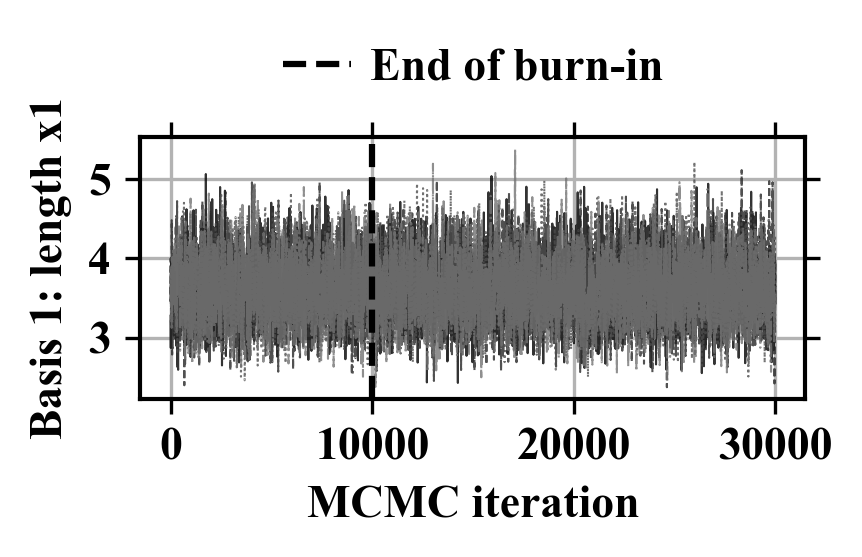

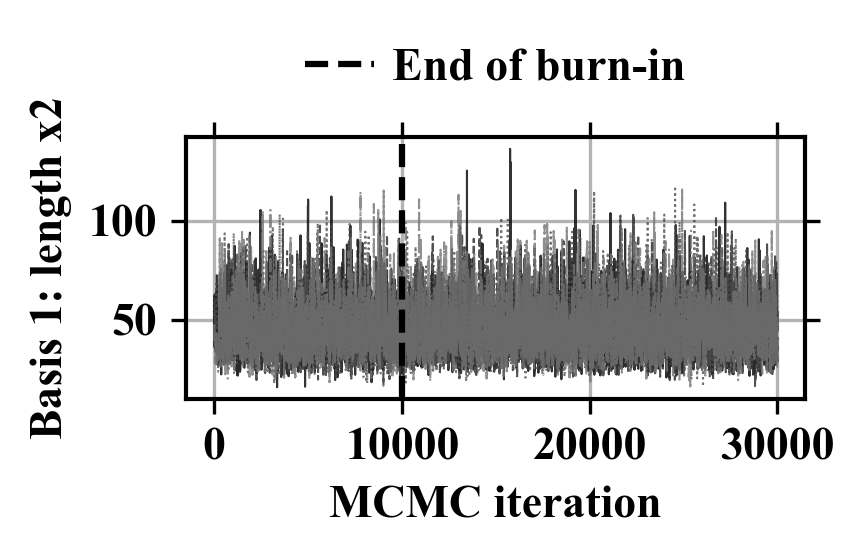

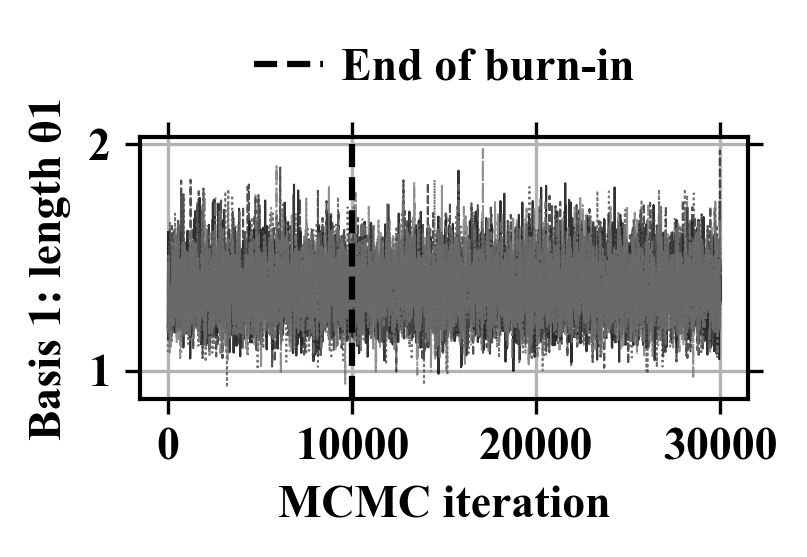

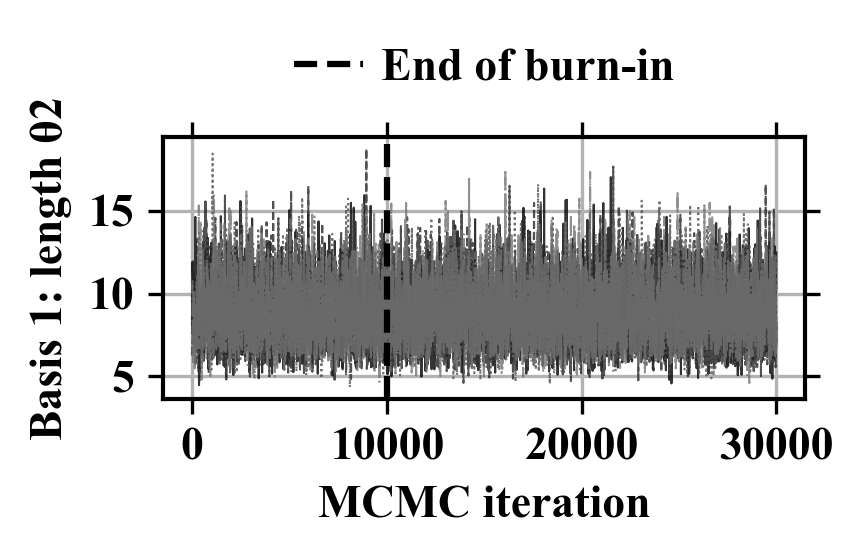

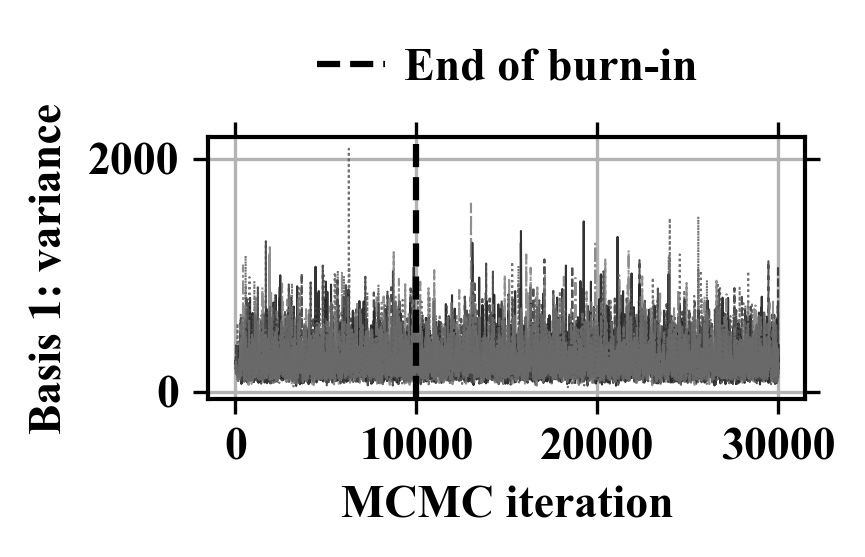

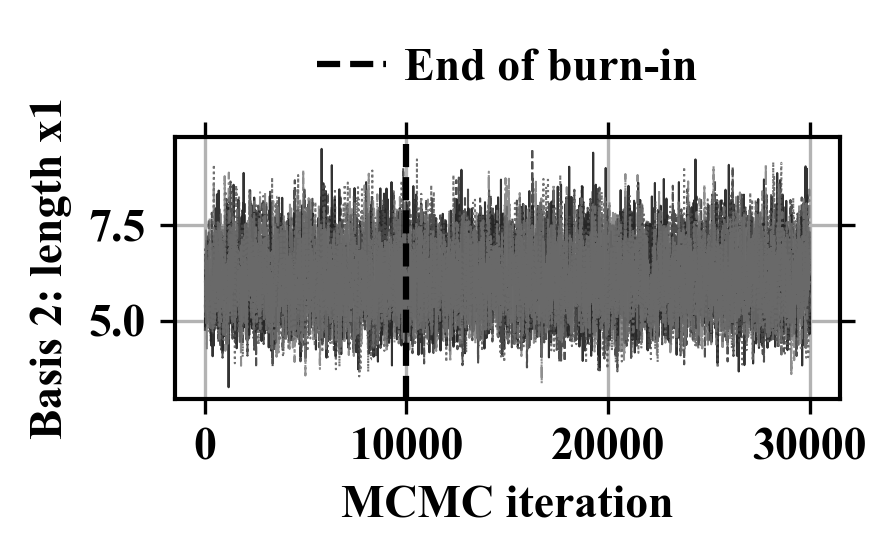

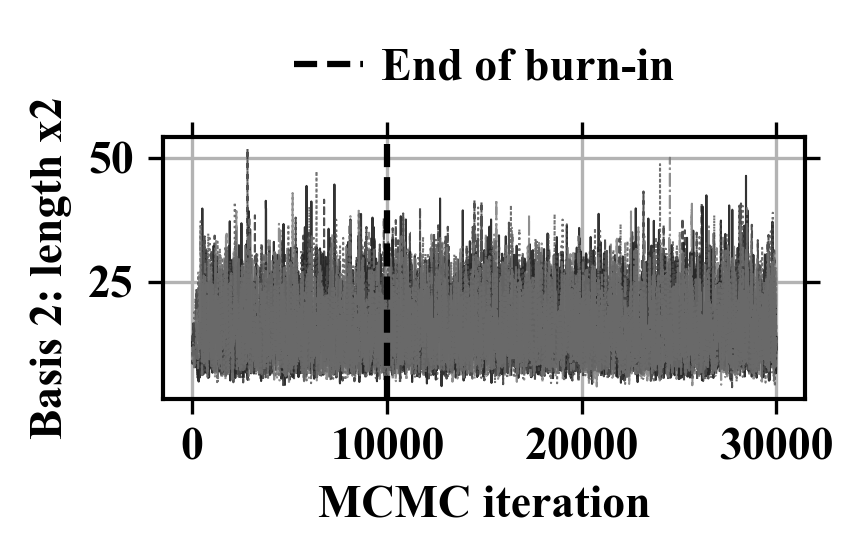

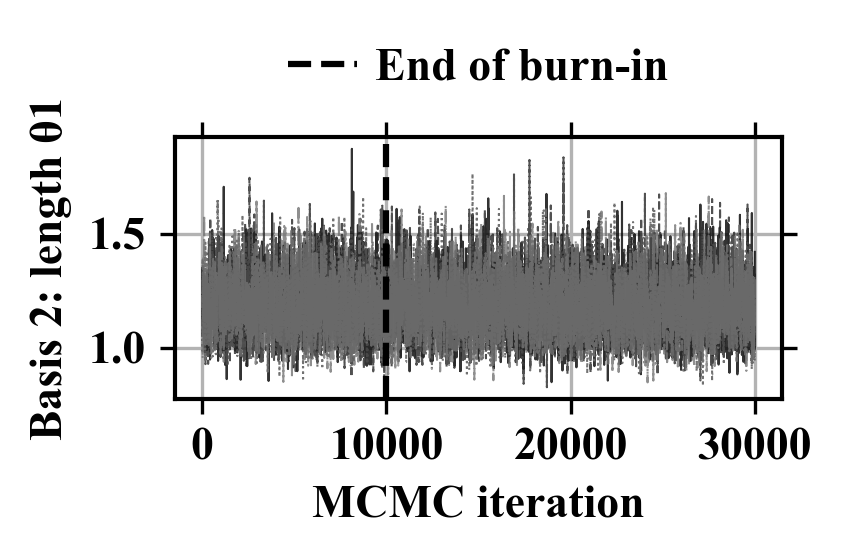

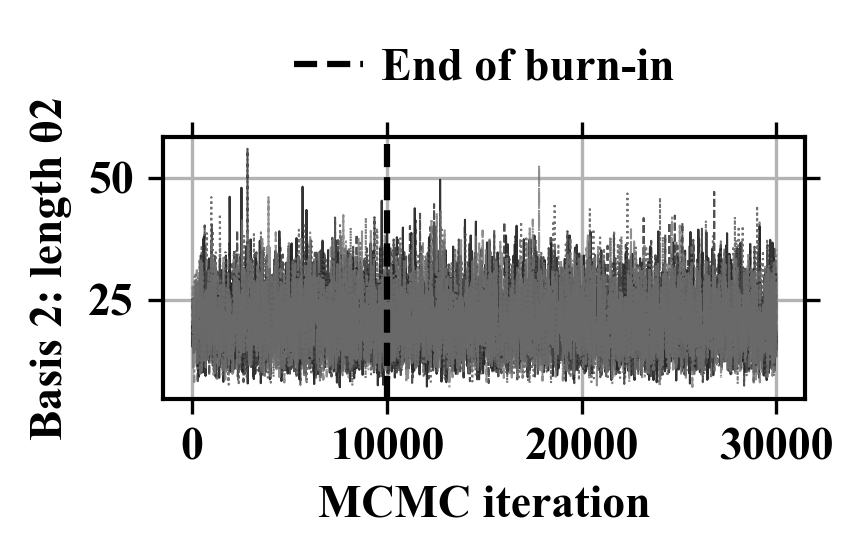

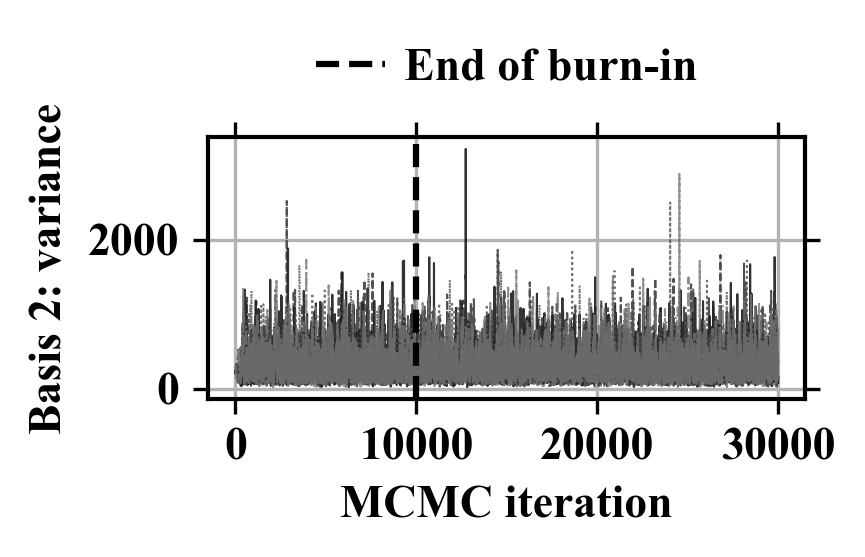

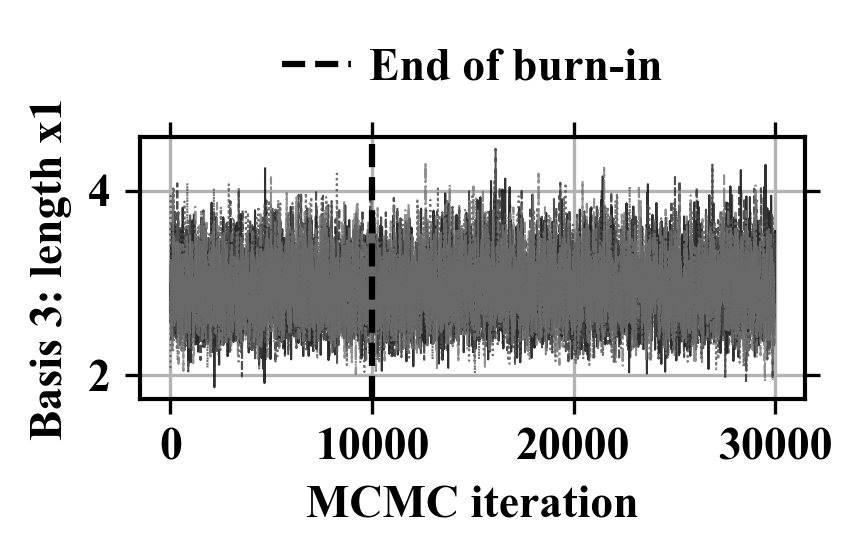

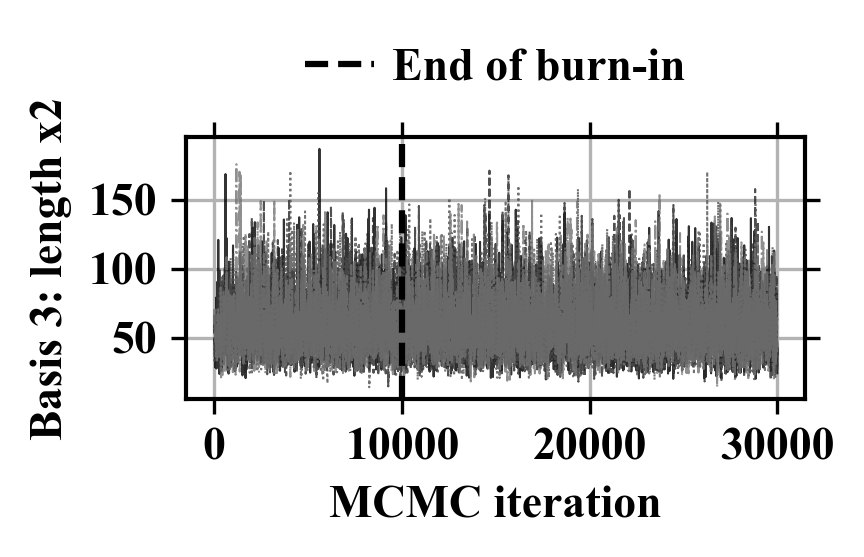

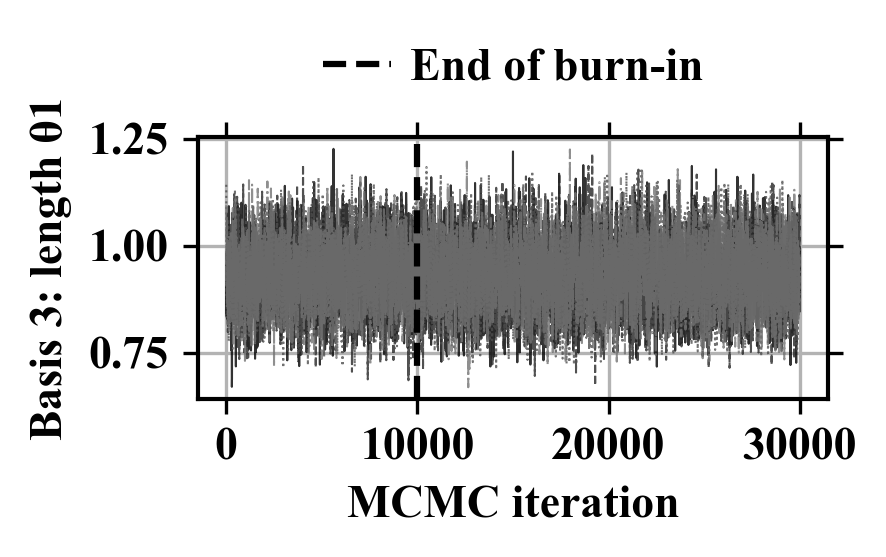

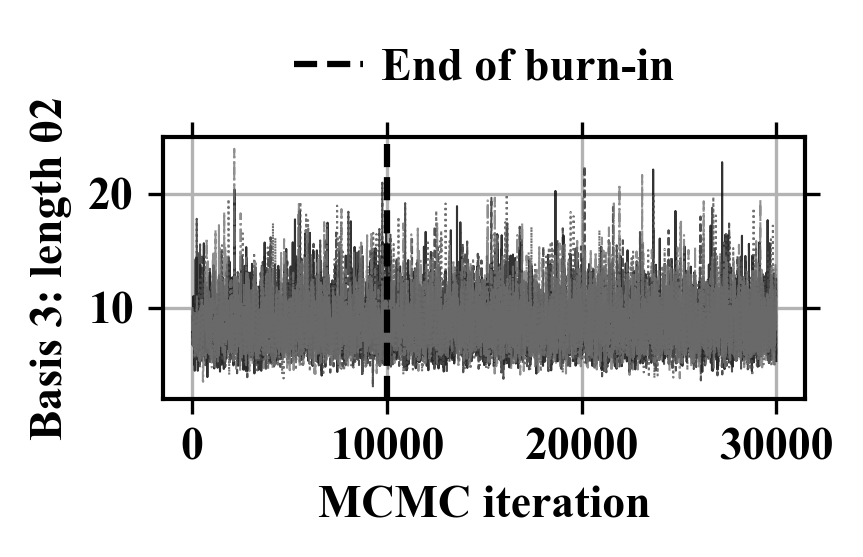

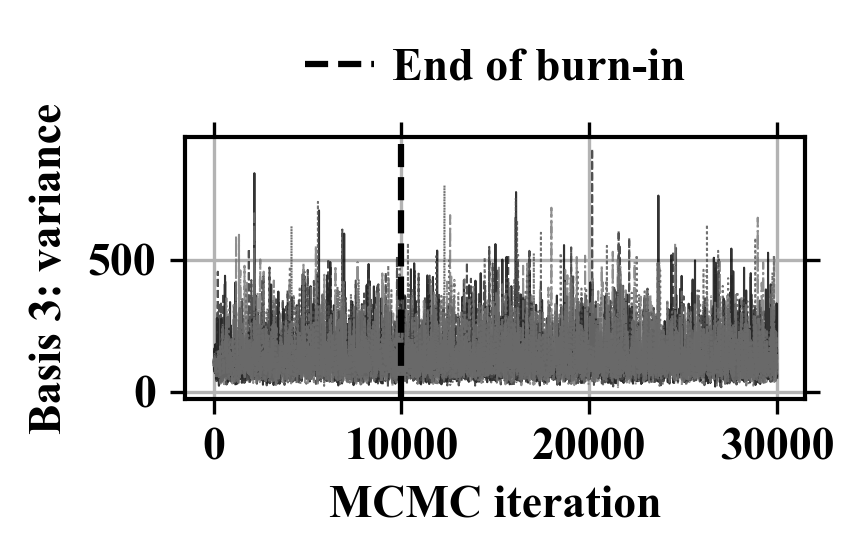

In [145]:
trace_styles = ['-', '--', ':', '-.']
for component in range(n_basis):
    for j, name in enumerate(parameter_names):
        fig, ax = plt.subplots(figsize=(3, 2))
        for chain_id in range(n_chains):
            ax.plot(np.arange(1, n_steps + 1), emulator_chains[component, chain_id, :, j],
                    color=str(0.15 * chain_id), linestyle=trace_styles[chain_id % 4], linewidth=0.5, alpha=0.8)
        ax.axvline(burn_in + 0.5, color='black', linestyle='--', label='End of burn-in')
        ax.set(xlabel='MCMC iteration', ylabel=f'Basis {component+1}: {name}')
        figure_legend(ax, ncol=1)
        fig.tight_layout()
        plt.show()

FREEZING THE EMULATOR AT POSTERIOR MEANS AND RECONSTRUCTING CURVE UNCERTAINTY

In [146]:
def prepare_emulator(parameters):
    factors, solves = [], []
    for j, row in enumerate(parameters):
        K = rbf_kernel(X_train, X_train, row[:4], row[4]) + alpha * training_eye
        L = cholesky(K, lower=True)
        factors.append(L)
        solves.append(cho_solve((L, True), weights_train[:, j], check_finite=False))
    return np.array(parameters, copy=True), factors, solves

frozen_emulator = prepare_emulator(frozen_parameters)
# Guard against accidental changes while calibration runs.
frozen_emulator[0].setflags(write=False)
frozen_parameters_before_calibration = frozen_emulator[0].copy()

def weight_prediction(inputs_unit, emulator):
    parameters, factors, solves = emulator
    means, covariances = [], []
    for j, row in enumerate(parameters):
        cross = rbf_kernel(X_train, inputs_unit, row[:4], row[4])
        v = solve_triangular(factors[j], cross, lower=True, check_finite=False)
        means.append(cross.T @ solves[j])
        covariances.append(rbf_kernel(inputs_unit, inputs_unit, row[:4], row[4]) - v.T @ v)
    return np.asarray(means).T, np.asarray(covariances)

def emulator_predict(x, theta, times, emulator=frozen_emulator):
    x, theta, times = np.asarray(x, float), np.asarray(theta, float), np.asarray(times, float)
    if times.ndim != 1 or x.shape != (len(times), 2) or theta.shape != (2,):
        raise ValueError('Expected x:(n,2), theta:(2,), times:(n,)')
    mean_time, basis_time = svd_basis_at_times(times)
    physical = np.column_stack((x, np.broadcast_to(theta, (len(x), 2))))
    if not np.all(np.isfinite(physical)) or np.any(physical < lower_bounds) or np.any(physical > upper_bounds):
        raise ValueError('Prediction inputs must be finite and within the simulator design bounds')
    inputs, inverse = np.unique((physical - lower_bounds) / (upper_bounds - lower_bounds), axis=0, return_inverse=True)
    weight_mean, weight_cov = weight_prediction(inputs, emulator)
    mean = mean_time + np.sum(basis_time * weight_mean[inverse], axis=1)
    covariance = np.zeros((len(times), len(times)))
    for j in range(n_basis):
        covariance += np.outer(basis_time[:, j], basis_time[:, j]) * weight_cov[j][inverse[:, None], inverse[None, :]]
    # Independent unresolved output residuals at distinct (x,t), shared for exact duplicates.
    coordinates = np.column_stack((x, times))
    same_coordinate = np.all(coordinates[:, None, :] == coordinates[None, :, :], axis=2)
    covariance += truncation_variance * same_coordinate
    return mean, (covariance + covariance.T) / 2

def frozen_emulator_predict(x, theta, times):
    return emulator_predict(x, theta, times, frozen_emulator)

def draw_joint_normal(mean, covariance, rng):
    covariance = (covariance + covariance.T) / 2
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    tolerance = 1e-8 * max(1.0, np.max(np.abs(np.diag(covariance))))
    if eigenvalues.min() < -tolerance:
        raise ValueError('Predictive covariance is not positive semidefinite')
    return mean + eigenvectors @ (np.sqrt(np.maximum(eigenvalues, 0.0)) * rng.normal(size=len(mean)))

HELD-OUT EMULATOR VALIDATION AND PURE REGRESSION CURVE

Held-out emulator RMSE: 0.001269 m
Empirical pointwise 90% interval coverage: 91.7% (descriptive; coordinates are correlated)


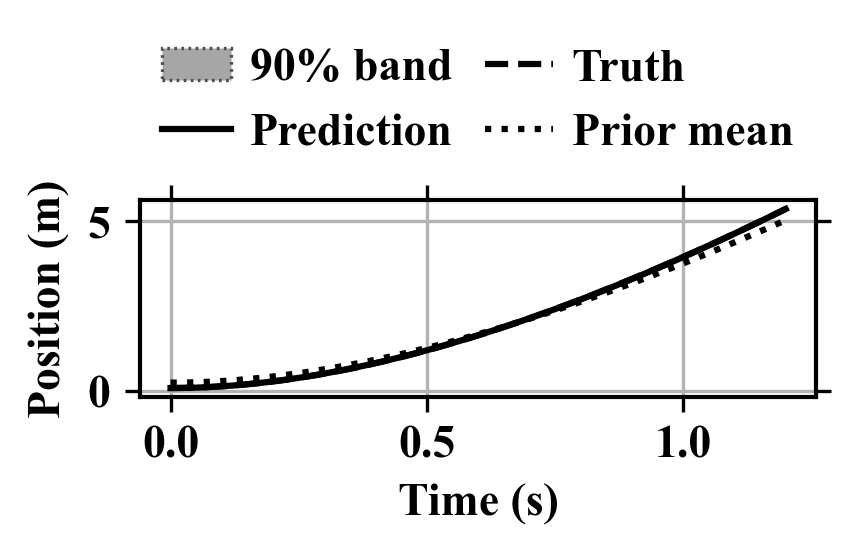

In [147]:
# All times in all held-out runs; no test curve was used for fitting or basis selection.
heldout_means, heldout_variances = [], []
for run in test_runs:
    x_grid = np.repeat(design[run:run+1, :2], len(time_sim), axis=0)
    mean, covariance = frozen_emulator_predict(x_grid, design[run, 2:], time_sim)
    heldout_means.append(mean)
    heldout_variances.append(np.maximum(np.diag(covariance), 0))
heldout_means, heldout_variances = np.array(heldout_means), np.array(heldout_variances)
heldout_rmse = np.sqrt(np.mean((y_test_raw - heldout_means)**2))
heldout_coverage = np.mean(np.abs(y_test_raw - heldout_means) <= norm.ppf(0.95) * np.sqrt(heldout_variances))
print(f'Held-out emulator RMSE: {heldout_rmse:.6f} m')
print(f'Empirical pointwise 90% interval coverage: {heldout_coverage:.1%} (descriptive; coordinates are correlated)')

time_plot = np.linspace(time_sim[0], time_sim[-1], 150)
x_plot = np.repeat(x_conditions[:1], len(time_plot), axis=0)
# Simulator-only plot integrates emulator hyperparameters; calibration below fixes them.
rng_regression = np.random.default_rng(123)
regression_draws, regression_means = [], []
with threadpool_limits(limits=1):
    for _ in range(200):
        sampled_parameters = np.array([emulator_posterior[j, rng_regression.integers(n_chains),
                                   rng_regression.integers(n_steps - burn_in)] for j in range(n_basis)])
        mean, covariance = emulator_predict(x_plot, theta_true, time_plot, prepare_emulator(sampled_parameters))
        regression_means.append(mean)
        regression_draws.append(draw_joint_normal(mean, covariance, rng_regression))
regression_lower, regression_upper = np.percentile(regression_draws, [5, 95], axis=0)
fig, ax = plt.subplots(figsize=(3, 2))
ax.fill_between(time_plot, regression_lower, regression_upper, facecolor='0.65', edgecolor='0.3', linestyle=':', linewidth=0.8, label='90% band')
ax.plot(time_plot, np.mean(regression_means, axis=0), 'k-', label='Prediction')
ax.plot(time_plot, physics_model(x_conditions[0], theta_true, time_plot), 'k--', label='Truth')
ax.plot(time_plot, svd_basis_at_times(time_plot)[0], 'k:', label='Prior mean')
ax.set(xlabel='Time (s)', ylabel='Position (m)')
figure_legend(ax, ncol=2)
fig.tight_layout()
plt.show()

DISCREPANCY BASIS AND ITS GP

Use \(\delta(x,t)=D(t)v(x)\). Five fixed smooth temporal basis functions represent
discrepancy; independent coefficient GPs share one length scale over the two normalized
experimental inputs and one physical-scale signal variance. Thus there are still two
discrepancy hyperparameters. This is an explicit basis/covariance choice, not a universal
GPMSA default. The basis is chosen without inspecting observations or synthetic truth.
The following cell projects this base covariance onto the complement of the emulator θ sensitivities. This does not guarantee that θ₁ and θ₂ are uncorrelated.

In [148]:
discrepancy_centers = np.linspace(0.0, 1.0, 5)
discrepancy_basis_width = 0.3

def discrepancy_basis(times):
    times = np.asarray(times, float)
    normalized = (times - time_sim[0]) / (time_sim[-1] - time_sim[0])
    D = np.exp(-0.5 * ((normalized[:, None] - discrepancy_centers) / discrepancy_basis_width)**2)
    # Row norm one makes signal_variance the marginal discrepancy variance.
    return D / np.sqrt(np.sum(D**2, axis=1, keepdims=True))

def base_discrepancy_covariance(x1, time1, x2, time2, lengthscale, signal_variance):
    x1_unit = (np.asarray(x1) - lower_bounds[:2]) / (upper_bounds[:2] - lower_bounds[:2])
    x2_unit = (np.asarray(x2) - lower_bounds[:2]) / (upper_bounds[:2] - lower_bounds[:2])
    return rbf_kernel(x1_unit, x2_unit, lengthscale, signal_variance) * (discrepancy_basis(time1) @ discrepancy_basis(time2).T)

PLUMLEE-STYLE ORTHOGONAL DISCREPANCY

With \(z=(x_1,x_2,t)\) and \(g_\theta(z)=\partial\widehat\eta(z,\theta)/\partial\theta\),
condition the discrepancy GP on \(\int g_\theta(z)\delta(z)\,d\mu(z)=0\).
The covariance becomes \(K_\perp=K-hH^+h^T\), where
\(h(z)=\int K(z,u)g_\theta(u)\,d\mu(u)\) and
\(H=\iint g_\theta(u)K(u,v)g_\theta(v)^T\,d\mu(u)d\mu(v)\).

The cell below uses uniform product Gauss–Legendre quadrature over the experimental
input bounds and the time interval, independently of the observation locations.
Sensitivities are analytic derivatives of the **frozen emulator mean**, recalculated
at each proposed θ. Emulator hyperparameters remain fixed. This implements
quadrature-approximated orthogonality to the emulator mean sensitivities, not to
every random emulator realization. It is an extension to the base GPMSA-style model.

**Interpretation:** this constraint targets a best-fitting L² calibration parameter.
The original synthetic discrepancy, 0.15 t², was not generated under this constraint,
so its generating θ need not equal that target. The synthetic L² reference computed
below is for validation only and does not enter the prior or likelihood.
See [Plumlee (2017), Bayesian Calibration of Inexact Computer Models](https://doi.org/10.1080/01621459.2016.1211016)
and [Plumlee and Joseph, Orthogonal Gaussian Process Models](https://arxiv.org/abs/1611.00203).

In [149]:
from numpy.polynomial.legendre import leggauss
from functools import lru_cache

USE_ORTHOGONAL_DISCREPANCY = True

def orthogonality_grid(order_x=4, order_time=12):
    nodes, weights = leggauss(order_x)
    u1, u2 = np.meshgrid((nodes+1)/2, (nodes+1)/2, indexing='ij')
    x_unit = np.column_stack((u1.ravel(), u2.ravel()))
    x = lower_bounds[:2] + x_unit * (upper_bounds[:2] - lower_bounds[:2])
    wx = np.outer(weights/2, weights/2).ravel()
    nodes_t, weights_t = leggauss(order_time)
    times = time_sim[0] + (nodes_t+1)/2 * (time_sim[-1] - time_sim[0])
    return x, wx, times, weights_t/2

orthogonal_x, orthogonal_wx, orthogonal_times, orthogonal_wt = orthogonality_grid()
orthogonal_x_unit = (orthogonal_x - lower_bounds[:2]) / (upper_bounds[:2] - lower_bounds[:2])
orthogonal_temporal_basis = svd_basis_at_times(orthogonal_times)[1]
orthogonal_D = discrepancy_basis(orthogonal_times)
temporal_projection = orthogonal_D.T @ (orthogonal_wt[:, None] * orthogonal_temporal_basis)

def weight_mean_theta_gradient(x, theta):
    x, theta = np.asarray(x, float), np.asarray(theta, float)
    physical = np.column_stack((x, np.broadcast_to(theta, (len(x), 2))))
    unit = (physical - lower_bounds) / (upper_bounds - lower_bounds)
    parameters, factors, solves = frozen_emulator
    gradient = np.empty((len(x), n_basis, 2))
    for j, row in enumerate(parameters):
        cross = rbf_kernel(X_train, unit, row[:4], row[4])
        for k in range(2):
            dimension = k + 2
            derivative = cross * (X_train[:, None, dimension] - unit[None, :, dimension])
            derivative /= row[dimension]**2 * (upper_bounds[dimension] - lower_bounds[dimension])
            gradient[:, j, k] = derivative.T @ solves[j]
    return gradient

def emulator_theta_gradient(x, theta, times):
    basis = svd_basis_at_times(times)[1]
    return np.einsum('np,npk->nk', basis, weight_mean_theta_gradient(x, theta))

@lru_cache(maxsize=32)
def _orthogonal_terms(theta1, theta2, lengthscale):
    derivatives = weight_mean_theta_gradient(orthogonal_x, np.array([theta1, theta2]))
    gradient_grid = np.einsum('tp,xpk->xtk', orthogonal_temporal_basis, derivatives)
    gradient_norm = np.sqrt(np.einsum('x,t,xtk->k', orthogonal_wx, orthogonal_wt, gradient_grid**2))
    if np.any(gradient_norm <= 1e-12):
        raise ValueError('A theta sensitivity vanishes on the orthogonality grid')
    # A[x,b,k] integrates D_b(t) times sensitivity k, including quadrature weights.
    A = orthogonal_wx[:, None, None] * np.einsum('bp,xpk->xbk', temporal_projection, derivatives)
    A /= gradient_norm
    R = rbf_kernel(orthogonal_x_unit, orthogonal_x_unit, lengthscale, 1.0)
    RA = (R @ A.reshape(len(orthogonal_x), -1)).reshape(A.shape)
    H = A.reshape(-1, 2).T @ RA.reshape(-1, 2)
    H = (H + H.T) / 2
    eigenvalues, eigenvectors = np.linalg.eigh(H)
    tolerance = max(eigenvalues.max(), np.finfo(float).tiny) * 1e-12
    active = eigenvalues > tolerance
    if not np.any(active):
        raise ValueError('Orthogonality constraints have no supported covariance directions')
    inverse = (eigenvectors[:, active] / eigenvalues[active]) @ eigenvectors[:, active].T
    return A, inverse

def discrepancy_covariance(x1, time1, x2, time2, lengthscale, signal_variance, theta):
    base = base_discrepancy_covariance(x1, time1, x2, time2, lengthscale, signal_variance)
    if not USE_ORTHOGONAL_DISCREPANCY:
        return base
    A, H_inverse = _orthogonal_terms(float(theta[0]), float(theta[1]), float(lengthscale))
    def cross_integral(x, times):
        x_unit = (np.asarray(x) - lower_bounds[:2]) / (upper_bounds[:2] - lower_bounds[:2])
        R = rbf_kernel(x_unit, orthogonal_x_unit, lengthscale, 1.0)
        RA = (R @ A.reshape(len(orthogonal_x), -1)).reshape(len(x), A.shape[1], 2)
        return np.einsum('nb,nbk->nk', discrepancy_basis(times), RA)
    h1, h2 = cross_integral(x1, time1), cross_integral(x2, time2)
    return base - signal_variance * (h1 @ H_inverse @ h2.T)

# Numerical orthogonality and derivative checks before running calibration.
theta_check = (lower_bounds[2:] + upper_bounds[2:]) / 2
qx = np.repeat(orthogonal_x, len(orthogonal_times), axis=0)
qt = np.tile(orthogonal_times, len(orthogonal_x))
qw = np.repeat(orthogonal_wx, len(orthogonal_times)) * np.tile(orthogonal_wt, len(orthogonal_x))
G = emulator_theta_gradient(qx, theta_check, qt)
K_orthogonal = discrepancy_covariance(qx, qt, qx, qt, 0.5, 1.0, theta_check)
weighted_gradient = qw[:, None] * G
relative_orthogonality_error = np.linalg.norm(K_orthogonal @ weighted_gradient) / max(np.linalg.norm(K_orthogonal) * np.linalg.norm(weighted_gradient), 1e-15)
assert relative_orthogonality_error < 1e-9
assert np.linalg.eigvalsh((K_orthogonal + K_orthogonal.T) / 2).min() > -1e-8
gradient_x, gradient_t = qx[:4], qt[:4]
analytic_gradient = emulator_theta_gradient(gradient_x, theta_check, gradient_t)
for k in range(2):
    step = 1e-4 * (upper_bounds[k+2] - lower_bounds[k+2])
    shift = np.eye(2)[k] * step
    plus = frozen_emulator_predict(gradient_x, theta_check + shift, gradient_t)[0]
    minus = frozen_emulator_predict(gradient_x, theta_check - shift, gradient_t)[0]
    np.testing.assert_allclose(analytic_gradient[:, k], (plus-minus)/(2*step), rtol=2e-3, atol=2e-5)
print(f'Orthogonal covariance weighted-gradient residual: {relative_orthogonality_error:.2e}')

# Synthetic L2 target under the same integration measure; not used to fit observations.
synthetic_reality_quadrature = physics_model(qx, theta_true, qt) + synthetic_discrepancy(qt)
def synthetic_l2_loss(theta):
    predicted = frozen_emulator_predict(qx, theta, qt)[0]
    return np.sum(qw * (synthetic_reality_quadrature - predicted)**2)
l2_result = minimize(synthetic_l2_loss, theta_check, method='Nelder-Mead',
                     bounds=list(zip(lower_bounds[2:], upper_bounds[2:])),
                     options={'xatol': 1e-7, 'fatol': 1e-12})
theta_l2_reference = l2_result.x
print('Generating theta:', theta_true, '; synthetic L2 reference:', theta_l2_reference)

Orthogonal covariance weighted-gradient residual: 1.38e-14
Generating theta: [0.8  1.05] ; synthetic L2 reference: [0.76708995 1.07894622]


CALIBRATION LIKELIHOOD WITH FROZEN EMULATOR COVARIANCE

In [150]:
calibration_jitter = 1e-10  # Numerical stabilization in physical covariance units.
observation_noise_cov = sigma_obs**2 * np.eye(len(y_obs))

def calibration_log_likelihood(theta, discrepancy_lengthscale, discrepancy_signal_variance):
    mean, emulator_cov = frozen_emulator_predict(x_obs, theta, t_obs)
    delta_cov = discrepancy_covariance(x_obs, t_obs, x_obs, t_obs,
                                       discrepancy_lengthscale, discrepancy_signal_variance, theta)
    covariance = emulator_cov + delta_cov + observation_noise_cov + calibration_jitter * np.eye(len(y_obs))
    try:
        L = cholesky(covariance, lower=True, check_finite=False)
    except np.linalg.LinAlgError:
        return -np.inf
    residual = solve_triangular(L, y_obs - mean, lower=True, check_finite=False)
    return -0.5 * residual @ residual - np.log(np.diag(L)).sum() - 0.5 * len(y_obs) * np.log(2 * np.pi)

CALIBRATION PRIORS AND POSTERIOR

In [151]:
# theta has independent uniform priors over its physical design bounds.
# The other priors retain the original notebook's scales.
discrepancy_variance_scale = (0.10 * svd_scale)**2

def transformed_calibration_log_posterior(z):
    theta = np.asarray(z[:2])
    if not np.all(np.isfinite(z)) or np.any(theta < lower_bounds[2:]) or np.any(theta > upper_bounds[2:]):
        return -np.inf
    with np.errstate(over='ignore', under='ignore', invalid='ignore'):
        lengthscale, variance = np.exp(z[2:])
    if not np.isfinite(lengthscale + variance) or min(lengthscale, variance) <= 0:
        return -np.inf
    # Normal priors in log coordinates already include the transformation Jacobians.
    log_prior = -0.5 * ((z[2] - np.log(0.5)) / 0.5)**2
    log_prior += -0.5 * ((z[3] - np.log(discrepancy_variance_scale)) / 0.7)**2
    try:
        value = calibration_log_likelihood(theta, lengthscale, variance) + log_prior
    except (np.linalg.LinAlgError, ValueError):
        return -np.inf
    return float(value) if np.isfinite(value) else -np.inf

initial_theta = np.array([1.0, 1.0])
initial_state = np.r_[initial_theta, np.log(0.5), np.log(discrepancy_variance_scale)]
print('Initial calibration log posterior (up to a constant):', transformed_calibration_log_posterior(initial_state))

Initial calibration log posterior (up to a constant): -287.3263922918954


CALIBRATION MCMC: ONLY θ₁, θ₂ AND THE TWO DISCREPANCY PARAMETERS CHANGE

In [152]:
calibration_transformed_chains = np.empty((n_chains, n_calibration_steps, 4))
calibration_accepted = np.empty((n_chains, n_calibration_steps), dtype=bool)
with threadpool_limits(limits=1):
    for chain_id in range(n_chains):
        rng_start = np.random.default_rng(2027 + chain_id)
        start = initial_state.copy()
        start[:2] = rng_start.uniform(lower_bounds[2:], upper_bounds[2:])
        start[2:] += rng_start.normal(0, 0.25, 2)
        chain, accepted = adaptive_metropolis(transformed_calibration_log_posterior, start,
                                             n_calibration_steps, calibration_burn_in,
                                             3027 + chain_id, np.array([0.05, 0.02, 0.1, 0.1]))
        calibration_transformed_chains[chain_id] = chain
        calibration_accepted[chain_id] = accepted
        print(f'Calibration chain {chain_id+1}: post-burn-in acceptance {accepted[calibration_burn_in:].mean():.3f}')
calibration_chains = calibration_transformed_chains.copy()
calibration_chains[:, :, 2:] = np.exp(calibration_chains[:, :, 2:])
calibration_posterior = calibration_chains[:, calibration_burn_in:, :]
calibration_posterior_samples = calibration_posterior.reshape(-1, 4)
calibration_parameter_names = ['θ₁', 'θ₂', 'Discrepancy length', 'Discrepancy variance']
calibration_diagnostics = mcmc_diagnostics(calibration_posterior, calibration_parameter_names)
print(calibration_diagnostics.to_string(index=False))
if (calibration_diagnostics.R_hat > 1.01).any() or (calibration_diagnostics.ESS_bulk < 400).any():
    print('CHECK: calibration convergence requires further assessment before interpreting intervals.')
assert np.array_equal(frozen_parameters_before_calibration, frozen_emulator[0])
print('Frozen emulator parameters unchanged. Retained samples:', calibration_posterior.shape)

Calibration chain 1: post-burn-in acceptance 0.277
Calibration chain 2: post-burn-in acceptance 0.284
Calibration chain 3: post-burn-in acceptance 0.105
Calibration chain 4: post-burn-in acceptance 0.284
           parameter  posterior_mean    R_hat    ESS_bulk
                  θ₁        0.788558 1.000564 4319.460183
                  θ₂        1.082422 1.000412 4357.435295
  Discrepancy length        0.613108 1.001530 3447.144205
Discrepancy variance        0.001586 1.001777 3490.896724
Frozen emulator parameters unchanged. Retained samples: (4, 20000, 4)


CALIBRATION TRACE PLOTS AND POSTERIOR MEANS

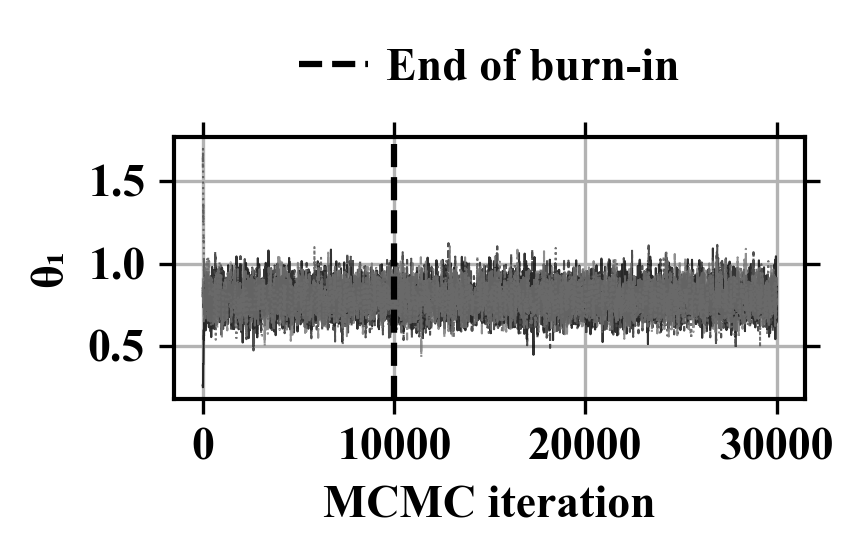

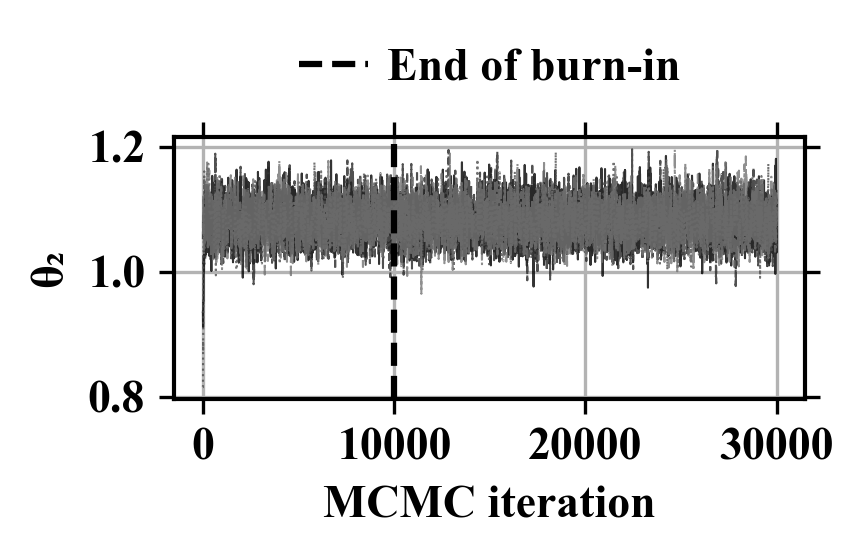

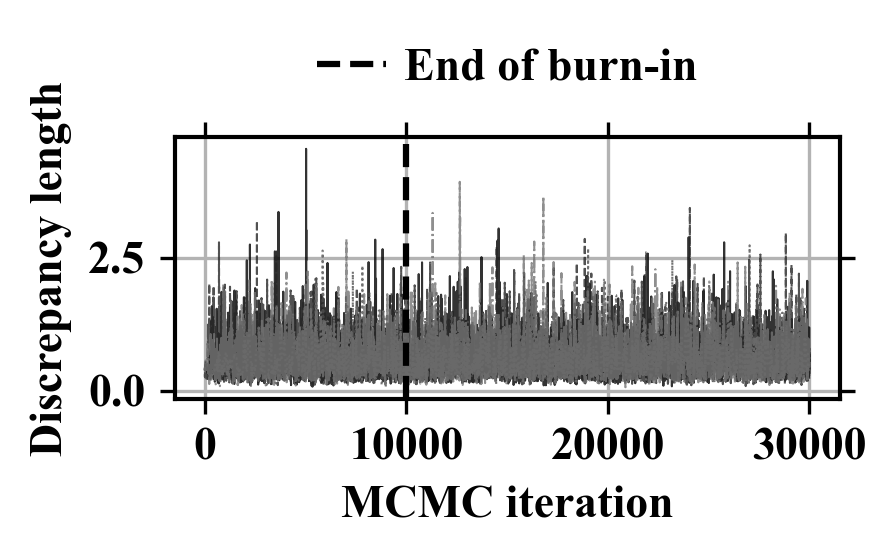

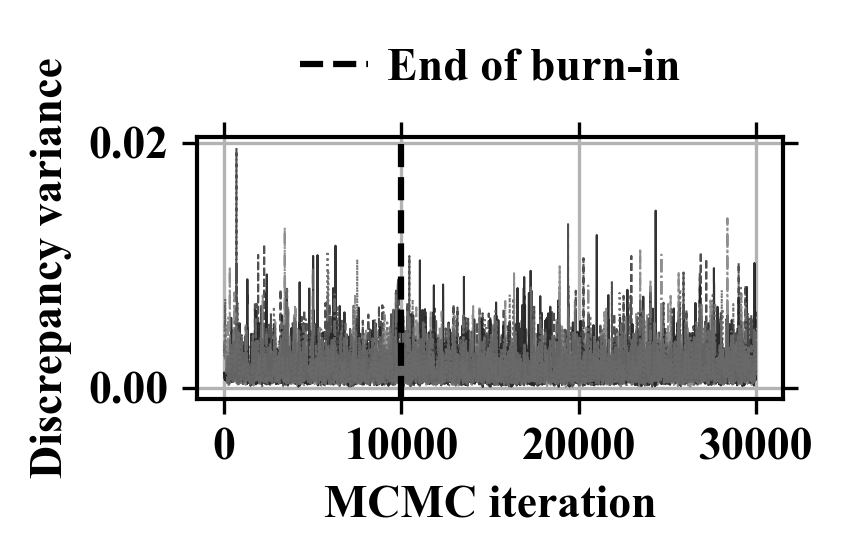

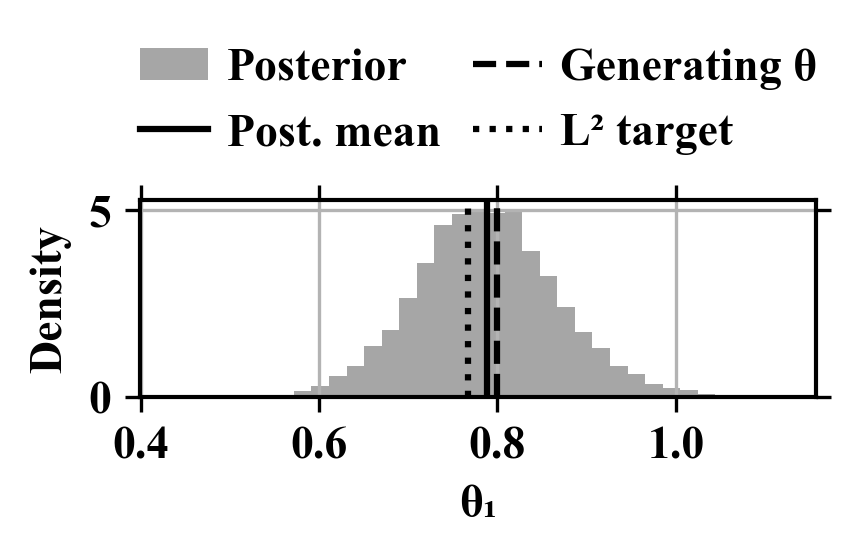

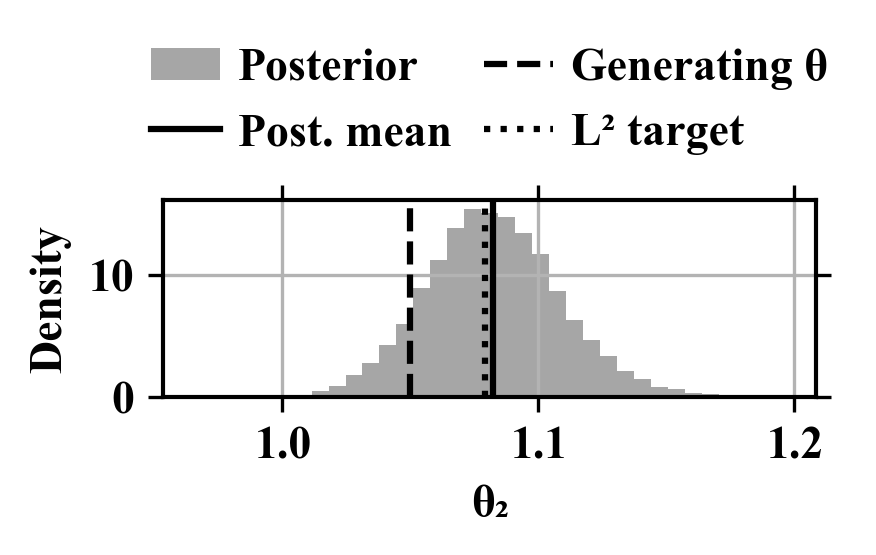

In [153]:
for j, label in enumerate(calibration_parameter_names):
    fig, ax = plt.subplots(figsize=(3, 2))
    for chain_id in range(n_chains):
        ax.plot(np.arange(1, n_calibration_steps+1), calibration_chains[chain_id, :, j],
                color=str(0.15 * chain_id), linestyle=trace_styles[chain_id % 4], linewidth=0.5, alpha=0.8)
    ax.axvline(calibration_burn_in + 0.5, color='black', linestyle='--', label='End of burn-in')
    ax.set(xlabel='MCMC iteration', ylabel=label)
    figure_legend(ax, ncol=1)
    fig.tight_layout()
    plt.show()

theta_posterior_mean = calibration_posterior_samples[:, :2].mean(axis=0)
for j in range(2):
    fig, ax = plt.subplots(figsize=(3, 2))
    ax.hist(calibration_posterior_samples[:, j], bins=35, density=True, color='0.65', label='Posterior')
    ax.axvline(theta_posterior_mean[j], color='black', label='Post. mean')
    ax.axvline(theta_true[j], color='black', linestyle='--', label='Generating θ')
    ax.axvline(theta_l2_reference[j], color='black', linestyle=':', label='L² target')
    ax.set(xlabel=calibration_parameter_names[j], ylabel='Density')
    figure_legend(ax, ncol=2)
    fig.tight_layout()
    plt.show()

JOINT PREDICTIONS FOR y WITH OBSERVATION NOISE

Each calibration draw supplies θ and discrepancy hyperparameters. Condition the
joint emulator-plus-discrepancy process on the observations, then sample a whole
correlated response vector. Add \(\sigma_{obs}^2 I\) **after conditioning** for future
independent measurement noise; the existing observation noise is also included
in the conditioning covariance. The band is the pointwise 5th–95th percentile
envelope for future noisy observations, not a simultaneous band. The plotted
prediction is the average conditional mean (less Monte Carlo noise than averaging
noisy realizations). The dashed truth is the noise-free synthetic response.

Experimental condition x = [0.85 0.1 ]
90% prediction-band width (min / mean / max): 0.1674 / 0.1800 / 0.2297 m
Noise-only normal 90% interval width: 0.1645 m


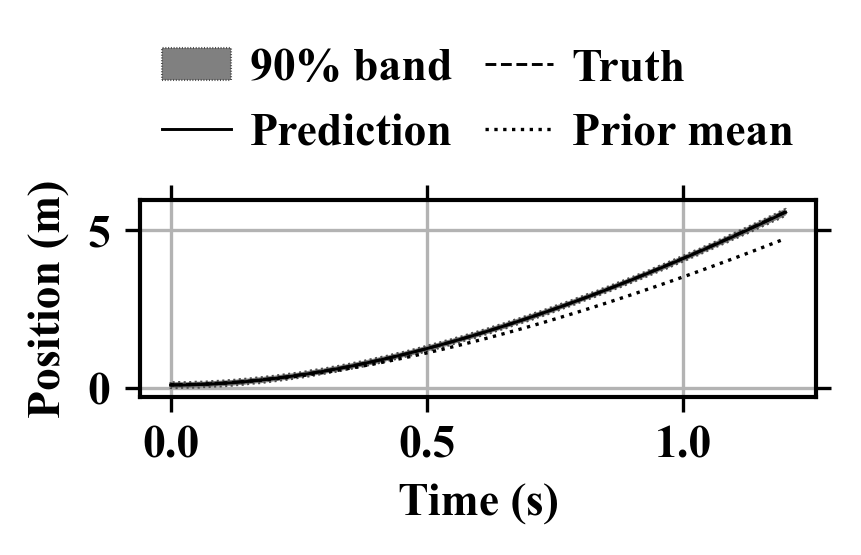

Uncertainty detail: deviations from the posterior mean


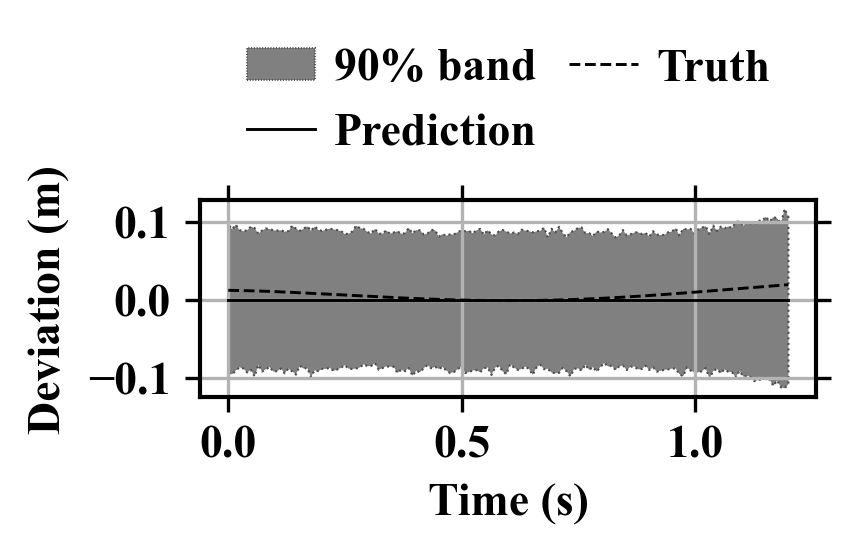

Experimental condition x = [1.15 0.4 ]
90% prediction-band width (min / mean / max): 0.1636 / 0.1777 / 0.2034 m
Noise-only normal 90% interval width: 0.1645 m


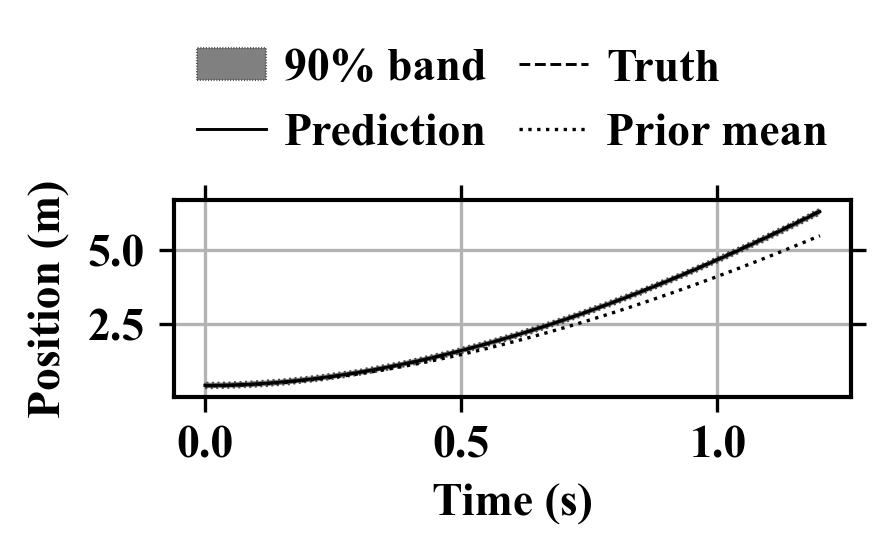

Uncertainty detail: deviations from the posterior mean


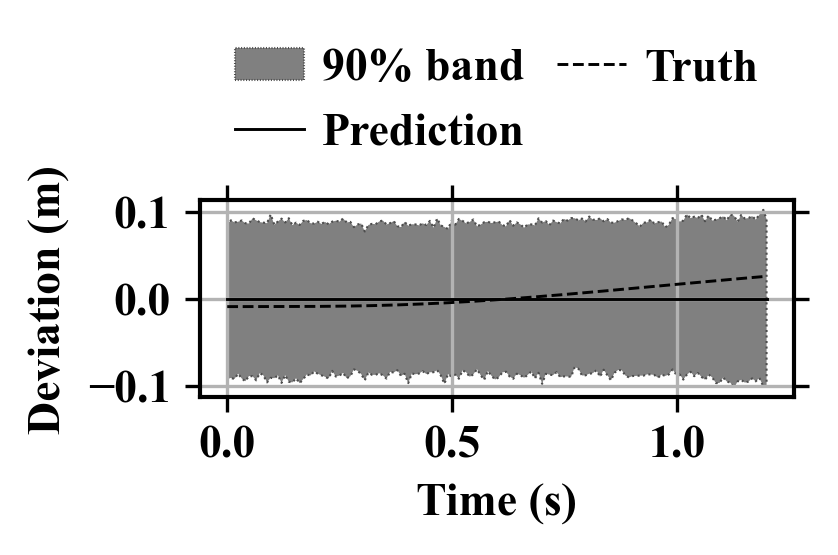

In [154]:
def conditional_response(x_new, times_new, parameters, include_observation_noise=True):
    theta, lengthscale, variance = parameters[:2], parameters[2], parameters[3]
    joint_x = np.vstack((x_obs, x_new))
    joint_t = np.concatenate((t_obs, times_new))
    mean, cov = frozen_emulator_predict(joint_x, theta, joint_t)
    cov += discrepancy_covariance(joint_x, joint_t, joint_x, joint_t, lengthscale, variance, theta)
    n_obs = len(y_obs)
    covariance_obs = cov[:n_obs, :n_obs] + observation_noise_cov + calibration_jitter * np.eye(n_obs)
    L = cholesky(covariance_obs, lower=True, check_finite=False)
    v = solve_triangular(L, cov[:n_obs, n_obs:], lower=True, check_finite=False)
    residual = solve_triangular(L, y_obs - mean[:n_obs], lower=True, check_finite=False)
    prediction_mean = mean[n_obs:] + v.T @ residual
    prediction_cov = cov[n_obs:, n_obs:] - v.T @ v
    prediction_cov = (prediction_cov + prediction_cov.T) / 2
    if include_observation_noise:
        prediction_cov += sigma_obs**2 * np.eye(len(times_new))
    return prediction_mean, prediction_cov

time_plot = np.linspace(time_sim[0], time_sim[-1], 150)
rng_prediction = np.random.default_rng(2028)
n_predictive_draws = min(1000, len(calibration_posterior_samples))
indices = rng_prediction.choice(len(calibration_posterior_samples), n_predictive_draws, replace=False)
prediction_results = []
with threadpool_limits(limits=1):
    for condition in x_conditions:
        x_plot = np.repeat(condition[None, :], len(time_plot), axis=0)
        draws, conditional_means, conditional_variances = [], [], []
        for index in indices:
            mean, covariance = conditional_response(x_plot, time_plot, calibration_posterior_samples[index])
            conditional_means.append(mean)
            conditional_variances.append(np.diag(covariance))
            draws.append(draw_joint_normal(mean, covariance, rng_prediction))
        draws, conditional_means = np.asarray(draws), np.asarray(conditional_means)
        lower, upper = np.percentile(draws, [5, 95], axis=0)
        # Total variance = E[conditional variance] + Var[conditional mean].
        total_variance = np.mean(conditional_variances, axis=0) + np.var(conditional_means, axis=0)
        prior_thetas = qmc.scale(qmc.LatinHypercube(d=2, seed=2028).random(100), lower_bounds[2:], upper_bounds[2:])
        prior = np.mean([frozen_emulator_predict(x_plot, theta, time_plot)[0] for theta in prior_thetas], axis=0)
        truth = physics_model(condition, theta_true, time_plot) + synthetic_discrepancy(time_plot)
        prediction_results.append(dict(x=condition.copy(), mean=conditional_means.mean(axis=0),
                                       lower=lower, upper=upper, variance=total_variance, draws=draws))
        print('Experimental condition x =', condition)
        band_width = upper - lower
        print(f'90% prediction-band width (min / mean / max): {band_width.min():.4f} / {band_width.mean():.4f} / {band_width.max():.4f} m')
        print(f'Noise-only normal 90% interval width: {2 * norm.ppf(0.95) * sigma_obs:.4f} m')
        fig, ax = plt.subplots(figsize=(3, 2))
        ax.fill_between(time_plot, lower, upper, facecolor='0.5', edgecolor='0.3', linestyle=':', linewidth=0.5, label='90% band', zorder=2)
        ax.plot(time_plot, conditional_means.mean(axis=0), 'k-', linewidth=0.7, label='Prediction', zorder=3)
        ax.plot(time_plot, truth, 'k--', linewidth=0.7, label='Truth', zorder=3)
        ax.plot(time_plot, prior, 'k:', linewidth=0.8, label='Prior mean')
        ax.set(xlabel='Time (s)', ylabel='Position (m)')
        figure_legend(ax, ncol=2)
        fig.tight_layout()
        plt.show()

        # The same band on a centered scale makes small uncertainty visible.
        # Only subtract the posterior mean; do not enlarge the interval.
        center = conditional_means.mean(axis=0)
        print('Uncertainty detail: deviations from the posterior mean')
        fig, ax = plt.subplots(figsize=(3, 2))
        ax.fill_between(time_plot, lower - center, upper - center, facecolor='0.5',
                        edgecolor='0.3', linestyle=':', linewidth=0.5, label='90% band')
        ax.plot(time_plot, np.zeros_like(time_plot), 'k-', linewidth=0.7, label='Prediction')
        ax.plot(time_plot, truth - center, 'k--', linewidth=0.7, label='Truth')
        ax.set(xlabel='Time (s)', ylabel='Deviation (m)')
        figure_legend(ax, ncol=2)
        fig.tight_layout()
        plt.show()

NUMERICAL CHECKS AND VALIDATION SUMMARY

In [155]:
# These checks test model identities, not whether chains have converged.
check_times = np.array([0.2, 0.5, 0.9])
check_x = np.repeat(x_conditions[:1], len(check_times), axis=0)
check_parameters = calibration_posterior_samples.mean(axis=0)
mean_latent, cov_latent = conditional_response(check_x, check_times, check_parameters, False)
mean_noisy, cov_noisy = conditional_response(check_x, check_times, check_parameters, True)
assert np.allclose(mean_latent, mean_noisy)
assert np.allclose(cov_noisy - cov_latent, sigma_obs**2 * np.eye(len(check_times)))
assert np.linalg.eigvalsh(cov_noisy).min() >= -1e-8

# Check duplicate coordinates share the same latent emulator value/covariance.
dup_mean, dup_cov = frozen_emulator_predict(np.repeat(x_conditions[:1], 2, axis=0), theta_true, np.array([0.4, 0.4]))
assert np.allclose(dup_mean[0], dup_mean[1]) and np.allclose(dup_cov[0], dup_cov[1])
assert np.array_equal(frozen_parameters_before_calibration, frozen_emulator[0])

# Hold-out interpolation check at off-grid times, independent of observation noise.
off_grid = (time_sim[:-1] + time_sim[1:]) / 2
mean_off, basis_off = svd_basis_at_times(off_grid)
off_reconstruction = mean_off + weights_test_projection @ basis_off.T
off_truth = np.array([physics_model(design[i, :2], design[i, 2:], off_grid) for i in test_runs])
interpolation_rmse = np.sqrt(np.mean((off_reconstruction - off_truth)**2))
print(f'Held-out off-grid basis reconstruction RMSE: {interpolation_rmse:.6f} m')
print('Checks passed: basis scaling, train/test separation, covariance PSD, fixed emulator, and future-noise variance.')
print('Emulator maximum R-hat:', emulator_diagnostics.R_hat.max())
print('Calibration maximum R-hat:', calibration_diagnostics.R_hat.max())
print('Inspect the diagnostic tables and held-out coverage before drawing scientific conclusions.')

Held-out off-grid basis reconstruction RMSE: 0.001168 m
Checks passed: basis scaling, train/test separation, covariance PSD, fixed emulator, and future-noise variance.
Emulator maximum R-hat: 1.001674919014164
Calibration maximum R-hat: 1.001777006616332
Inspect the diagnostic tables and held-out coverage before drawing scientific conclusions.


PRIOR, POSTERIOR, DISCREPANCY AND REALITY PLOTS

The four plot types below share one 2-by-2, 6-by-4-inch figure for each experimental
condition (approximately 3-by-2 inches per panel). “Prior” means the emulator after training on simulator runs but before
conditioning on the experimental observations, with θ sampled from its uniform prior.
Posterior emulator and discrepancy curves are drawn **jointly**, retaining their
posterior cross-covariance. Their sum gives the latent physical response.
Independent sensor noise is added for the final observation prediction band.
All plotted point estimates are posterior means. Experimental error bars show
the known 90% normal measurement-error interval, ±1.645 σ_obs.

In [156]:
def calibrated_components(x_new, times_new, parameters):
    """Joint posterior of [emulator curve, discrepancy curve], conditional on data."""
    theta, delta_length, delta_variance = parameters[:2], parameters[2], parameters[3]
    joint_x = np.vstack((x_obs, x_new))
    joint_times = np.concatenate((t_obs, times_new))
    emulator_mean, E = frozen_emulator_predict(joint_x, theta, joint_times)
    D = discrepancy_covariance(joint_x, joint_times, joint_x, joint_times, delta_length, delta_variance, theta)
    n_obs, n_new = len(y_obs), len(times_new)
    covariance_obs = E[:n_obs, :n_obs] + D[:n_obs, :n_obs] + observation_noise_cov + calibration_jitter * np.eye(n_obs)
    L = cholesky(covariance_obs, lower=True, check_finite=False)
    cross = np.concatenate((E[:n_obs, n_obs:], D[:n_obs, n_obs:]), axis=1)
    solved_cross = solve_triangular(L, cross, lower=True, check_finite=False)
    residual = solve_triangular(L, y_obs - emulator_mean[:n_obs], lower=True, check_finite=False)
    prior_mean = np.r_[emulator_mean[n_obs:], np.zeros(n_new)]
    prior_covariance = np.zeros((2*n_new, 2*n_new))
    prior_covariance[:n_new, :n_new] = E[n_obs:, n_obs:]
    prior_covariance[n_new:, n_new:] = D[n_obs:, n_obs:]
    posterior_covariance = prior_covariance - solved_cross.T @ solved_cross
    return prior_mean + solved_cross.T @ residual, (posterior_covariance + posterior_covariance.T) / 2

# Check that the sum of the component distributions equals the direct reality prediction.
check_mean, check_covariance = calibrated_components(check_x, check_times, check_parameters)
k = len(check_times)
sum_covariance = (check_covariance[:k, :k] + check_covariance[k:, k:]
                  + check_covariance[:k, k:] + check_covariance[k:, :k])
np.testing.assert_allclose(check_mean[:k] + check_mean[k:], mean_latent, atol=1e-8)
np.testing.assert_allclose(sum_covariance, cov_latent, atol=1e-8)
print('Component means and cross-covariance reproduce the latent reality prediction.')

Component means and cross-covariance reproduce the latent reality prediction.


Prior / posterior / discrepancy / reality; condition x = [0.85 0.1 ]


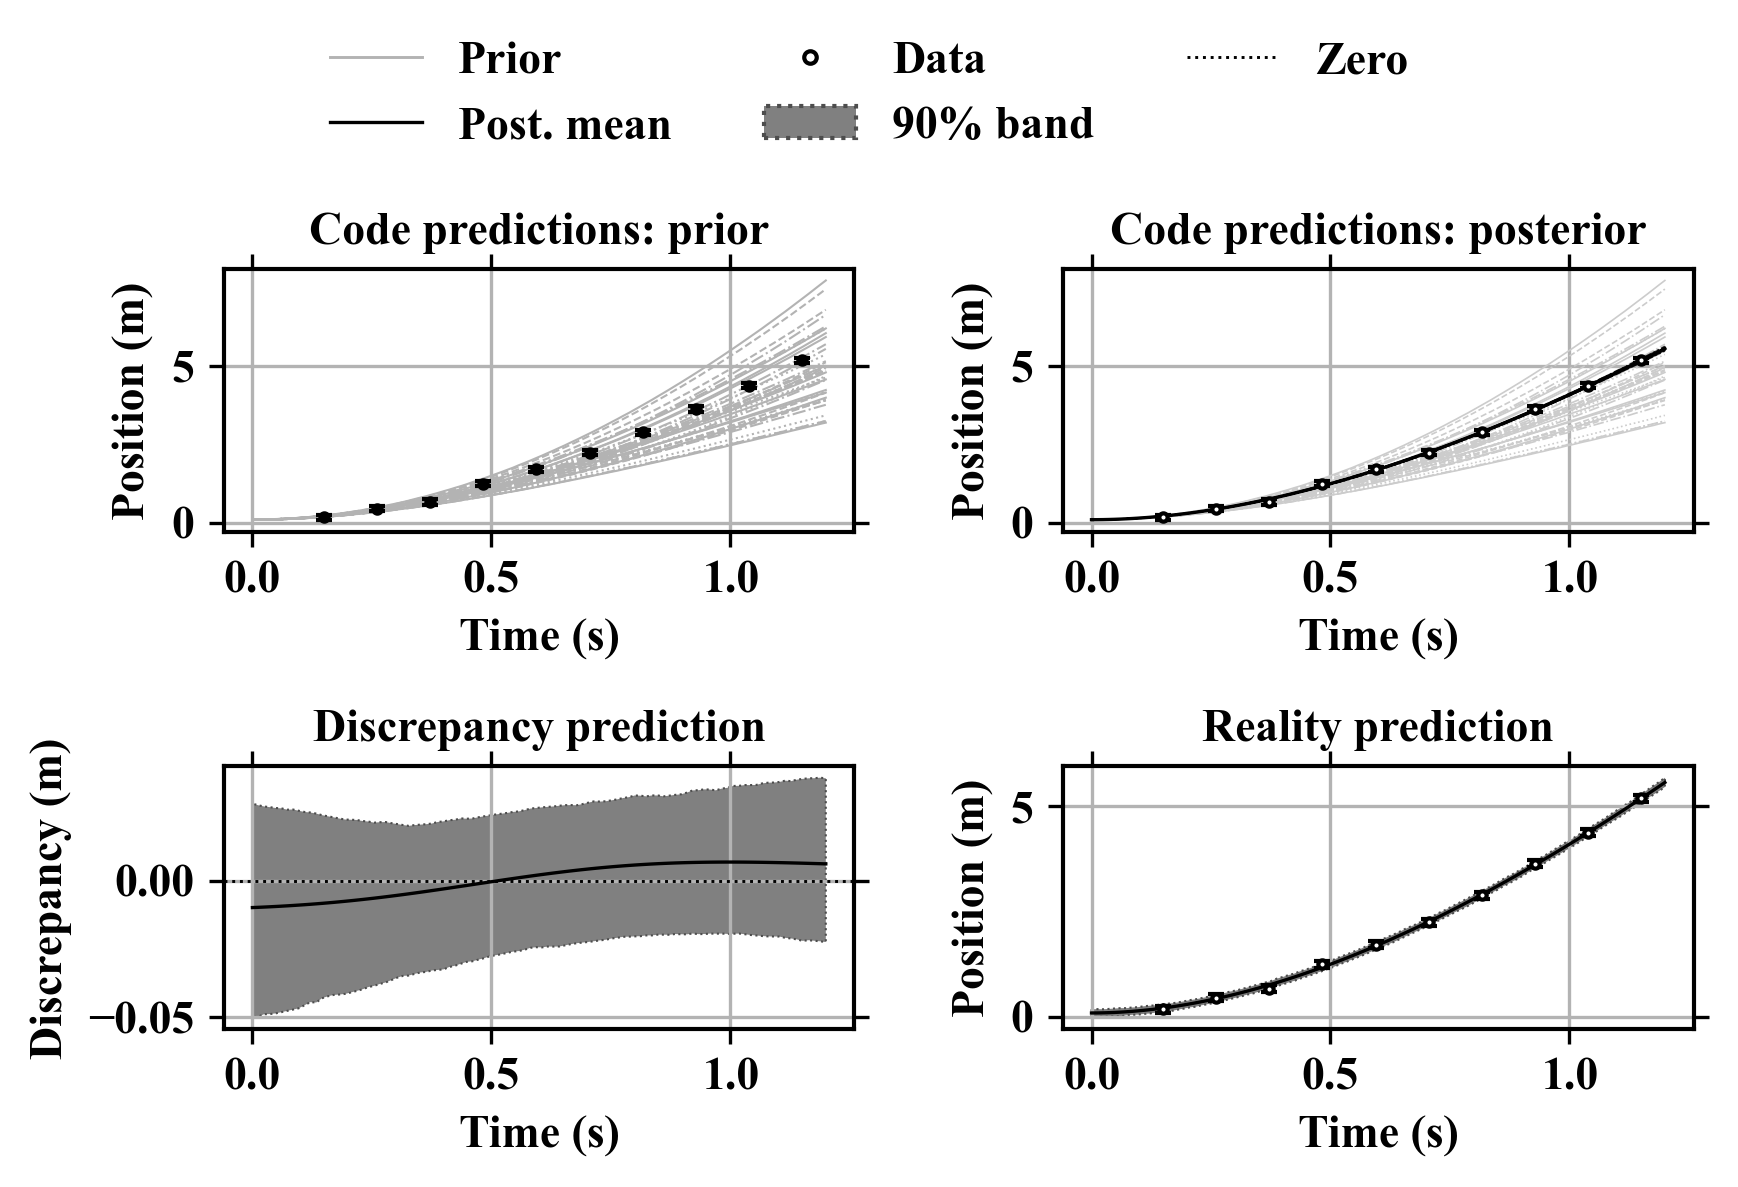

Prior / posterior / discrepancy / reality; condition x = [1.15 0.4 ]


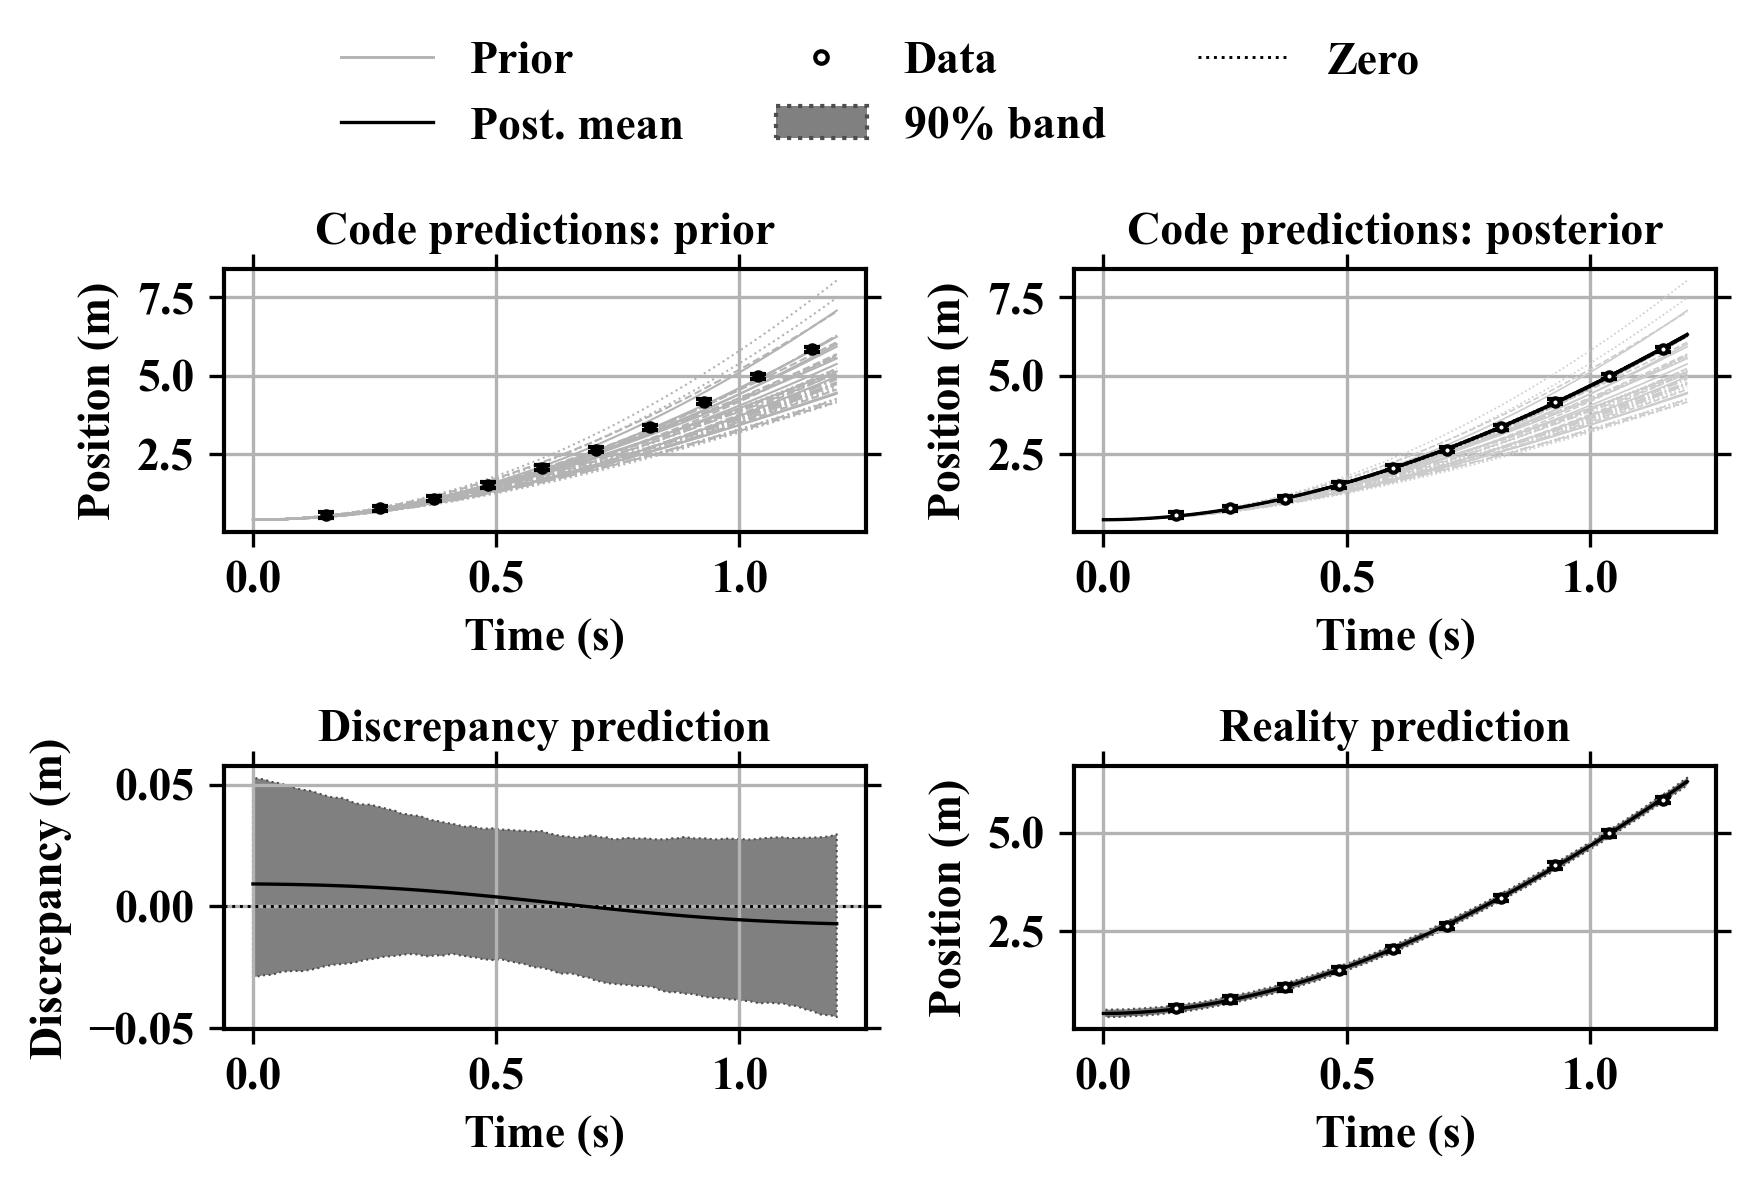

In [157]:
rng_components = np.random.default_rng(2029)
time_components = np.linspace(time_sim[0], time_sim[-1], 100)
n_component_draws = min(1000, len(calibration_posterior_samples))
component_indices = rng_components.choice(len(calibration_posterior_samples), n_component_draws, replace=False)
component_plot_results = []

with threadpool_limits(limits=1):
    for condition in x_conditions:
        x_grid = np.repeat(condition[None, :], len(time_components), axis=0)
        selected_observations = np.all(x_obs == condition, axis=1)
        observed_times = t_obs[selected_observations]
        observed_values = y_obs[selected_observations]
        prior_curves = []
        for _ in range(40):
            theta = rng_components.uniform(lower_bounds[2:], upper_bounds[2:])
            mean, covariance = frozen_emulator_predict(x_grid, theta, time_components)
            prior_curves.append(draw_joint_normal(mean, covariance, rng_components))

        emulator_draws, discrepancy_draws, reality_draws = [], [], []
        emulator_means, discrepancy_means = [], []
        for index in component_indices:
            mean, covariance = calibrated_components(x_grid, time_components, calibration_posterior_samples[index])
            joint_draw = draw_joint_normal(mean, covariance, rng_components)
            k = len(time_components)
            emulator_means.append(mean[:k])
            discrepancy_means.append(mean[k:])
            emulator_draws.append(joint_draw[:k])
            discrepancy_draws.append(joint_draw[k:])
            reality_draws.append(joint_draw[:k] + joint_draw[k:] + rng_components.normal(0, sigma_obs, k))
        emulator_draws, discrepancy_draws, reality_draws = map(np.asarray, (emulator_draws, discrepancy_draws, reality_draws))
        emulator_mean = np.mean(emulator_means, axis=0)
        discrepancy_mean = np.mean(discrepancy_means, axis=0)
        delta_lower, delta_upper = np.percentile(discrepancy_draws, [5, 95], axis=0)
        reality_lower, reality_upper = np.percentile(reality_draws, [5, 95], axis=0)
        reality_mean = emulator_mean + discrepancy_mean
        component_plot_results.append(dict(x=condition.copy(), emulator_mean=emulator_mean,
            discrepancy_mean=discrepancy_mean, discrepancy_lower=delta_lower, discrepancy_upper=delta_upper,
            reality_mean=reality_mean, reality_lower=reality_lower, reality_upper=reality_upper))


        print('Prior / posterior / discrepancy / reality; condition x =', condition)
        fig, axes = plt.subplots(2, 2, figsize=(6, 4))
        ax = axes[0, 0]
        for curve in prior_curves:
            ax.plot(time_components, curve, color='0.7', linewidth=0.5)
        ax.errorbar(observed_times, observed_values, yerr=norm.ppf(0.95)*sigma_obs,
                    fmt='ko', markersize=2, capsize=2, linewidth=0.6)
        ax.set_title('Code predictions: prior')
        ax.set_ylabel('Position (m)')

        ax = axes[0, 1]
        for curve in prior_curves:
            ax.plot(time_components, curve, color='0.8', linewidth=0.4)
        for curve in emulator_draws[:40]:
            ax.plot(time_components, curve, color='black', linewidth=0.4, alpha=0.4)
        ax.plot(time_components, emulator_mean, 'k-', linewidth=0.8)
        ax.errorbar(observed_times, observed_values, yerr=norm.ppf(0.95)*sigma_obs,
                    fmt='ko', markerfacecolor='white', markersize=2, capsize=2, linewidth=0.6)
        ax.set_title('Code predictions: posterior')
        ax.set_ylabel('Position (m)')

        ax = axes[1, 0]
        ax.fill_between(time_components, delta_lower, delta_upper, facecolor='0.5', edgecolor='0.3',
                        linestyle=':', linewidth=0.5)
        ax.plot(time_components, discrepancy_mean, 'k-', linewidth=0.8)
        ax.axhline(0, color='black', linestyle=':', linewidth=0.7)
        ax.set_title('Discrepancy prediction')
        ax.set_ylabel('Discrepancy (m)')

        ax = axes[1, 1]
        ax.fill_between(time_components, reality_lower, reality_upper, facecolor='0.5', edgecolor='0.3',
                        linestyle=':', linewidth=0.5)
        ax.plot(time_components, reality_mean, 'k-', linewidth=0.8)
        ax.errorbar(observed_times, observed_values, yerr=norm.ppf(0.95)*sigma_obs,
                    fmt='ko', markerfacecolor='white', markersize=2, capsize=2, linewidth=0.6)
        ax.set_title('Reality prediction')
        ax.set_ylabel('Position (m)')
        for ax in axes.ravel():
            ax.set_xlabel('Time (s)')
        from matplotlib.lines import Line2D
        from matplotlib.patches import Patch
        handles = [Line2D([], [], color='0.7', linewidth=0.7, label='Prior'),
                   Line2D([], [], color='black', linewidth=0.8, label='Post. mean'),
                   Line2D([], [], color='black', marker='o', markerfacecolor='white', linestyle='none', markersize=3, label='Data'),
                   Patch(facecolor='0.5', edgecolor='0.3', linestyle=':', label='90% band'),
                   Line2D([], [], color='black', linestyle=':', linewidth=0.7, label='Zero')]
        fig.legend(handles=handles, loc='upper center', ncol=3, frameon=False)
        fig.tight_layout(rect=(0, 0, 1, 0.87))
        plt.show()


JOINT POSTERIOR OF θ₁ AND θ₂

Diagonal panels show the one-dimensional posterior histograms and posterior means.
Off-diagonal panels show the dependence between the two calibration parameters,
with approximate 50% and 90% highest-density contours from a Gaussian KDE.
These are density estimates, not additional MCMC fits. Axes use physical θ units.

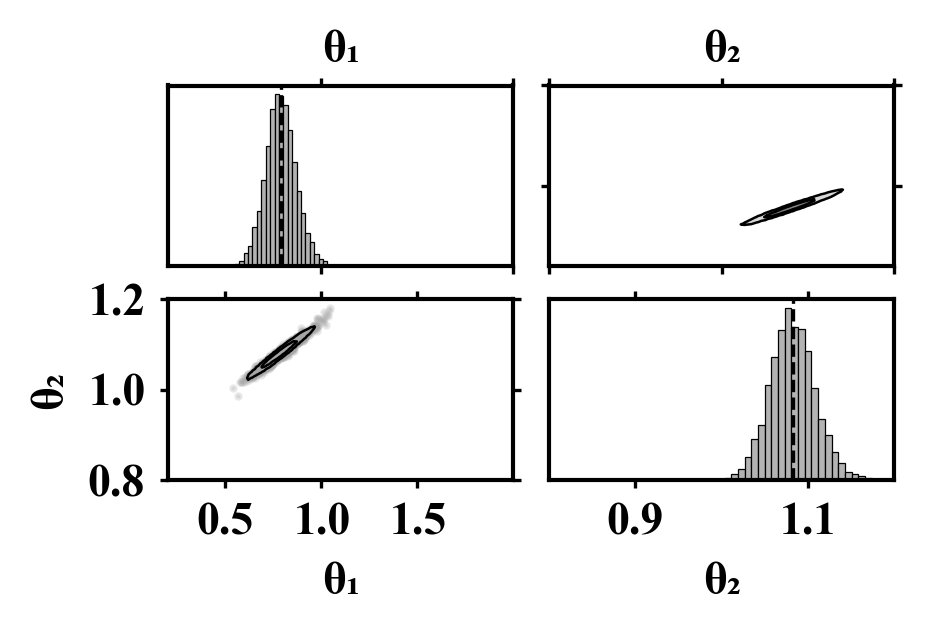

Posterior means θ₁, θ₂: [0.7885577  1.08242245]
Posterior correlation: 0.97835330580142


In [158]:
from scipy.stats import gaussian_kde

theta_draws = calibration_posterior_samples[:, :2]
rng_pair = np.random.default_rng(2030)
kde_draws = theta_draws[rng_pair.choice(len(theta_draws), min(4000, len(theta_draws)), replace=False)]
kde = gaussian_kde(kde_draws.T)
theta1_grid = np.linspace(lower_bounds[2], upper_bounds[2], 100)
theta2_grid = np.linspace(lower_bounds[3], upper_bounds[3], 100)
grid1, grid2 = np.meshgrid(theta1_grid, theta2_grid)
density = kde(np.vstack((grid1.ravel(), grid2.ravel()))).reshape(grid1.shape)
sorted_density = np.sort(density.ravel())[::-1]
cumulative_mass = np.cumsum(sorted_density) / sorted_density.sum()
levels = sorted([sorted_density[np.searchsorted(cumulative_mass, p)] for p in (0.5, 0.9)])

fig, axes = plt.subplots(2, 2, figsize=(3, 2))
for j in range(2):
    axes[j, j].hist(theta_draws[:, j], bins=30, density=True, color='0.7', edgecolor='black', linewidth=0.3)
    axes[j, j].axvline(theta_draws[:, j].mean(), color='black', linestyle='--', linewidth=0.8)
    axes[j, j].set_xlim(lower_bounds[2+j], upper_bounds[2+j])
    axes[j, j].set_yticks([])
axes[1, 0].scatter(kde_draws[::4, 0], kde_draws[::4, 1], s=1, color='0.65', alpha=0.25, rasterized=True)
axes[1, 0].contour(grid1, grid2, density, levels=levels, colors='black', linewidths=0.6)
axes[0, 1].contourf(grid2.T, grid1.T, density.T,
                    levels=[0, *levels, density.max() * 1.001], colors=['white', '0.85', '0.5'])
axes[0, 1].contour(grid2.T, grid1.T, density.T, levels=levels, colors='black', linewidths=0.6)
axes[1, 0].set(xlim=(lower_bounds[2], upper_bounds[2]), ylim=(lower_bounds[3], upper_bounds[3]), xlabel='θ₁', ylabel='θ₂')
axes[0, 1].set(xlim=(lower_bounds[3], upper_bounds[3]), ylim=(lower_bounds[2], upper_bounds[2]))
axes[1, 1].set_xlabel('θ₂')
axes[0, 0].set_title('θ₁')
axes[0, 1].set_title('θ₂')
for ax in axes[0]:
    ax.tick_params(labelbottom=False)
axes[0, 1].tick_params(labelleft=False)
for ax in axes.ravel():
    ax.grid(False)
    ax.locator_params(axis='x', nbins=2)
    ax.tick_params(length=2)
axes[1, 0].locator_params(axis='y', nbins=2)
axes[1, 0].set_xticks([0.5, 1.0, 1.5])
axes[1, 1].set_xticks([0.9, 1.1])
fig.tight_layout(pad=0.3, h_pad=0.2, w_pad=0.6)
plt.show()
print('Posterior means θ₁, θ₂:', theta_draws.mean(axis=0))
print('Posterior correlation:', np.corrcoef(theta_draws.T)[0, 1])